## Results/figures for Texas and Louisiana CCS
These are calculations, figures, and tables to support the writing of the paper [*Federally subsidized carbon capture and storage supports a methane-based industrial buildout and provides little or no emissions benefit*](https://docs.google.com/document/d/12xr6uktQcX6xO7qUZsigWMY7c9J2TvCPBhCqnJbQ20U/edit?usp=sharing), submitted to Environmental Research -- Energy November 2026

In [41]:
from datetime import datetime as dt
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.image as mpimg
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ccs_ghg.helpers.figs_tables import (
    INDUSTRY_MARKERS,
    _DEFAULT_INDUSTRIES,
    _NAME_REPLACEMENTS,
    _compute_panel_data,
    build_multi_scenario_summary,
    compute_buildout_lifetime,
    compute_counterfactual_totals,
    compute_scenario_totals,
    plot_emissions_breakdown_combined,
    plot_emissions_through_time,
    plot_facility_map,
    plot_industry_sankey,
    plot_lifetime_delta_vs_unabated,
    plot_lifetime_emissions_vs_leak_rate,
    plot_profit_vs_emissions,
    plot_state_emissions_vs_unabated_and_existing,
    plot_state_sankey,
    plot_two_panel,
    scenario_oil_and_emissions_table,
    summarize_state_scenarios,
    table5_scenario_emissions,
    build_table_s2,
)

warnings.filterwarnings("ignore")
%load_ext jupyter_black

from ccs_ghg.paths import DEV_DIR, DATA_DIR as _EXT_DATA

DATA_DIR = DEV_DIR / "projects" / "ccs_ghg" / "data"  # pipeline CSVs
GEO_DIR = _EXT_DATA  # external shapefiles / aux data
FIG_DIR = Path("projects/ccs_ghg/figures_for_paper")
FIG_DIR.mkdir(exist_ok=True)

The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black


## Data

### Load pipeline output data

In [2]:
# Load pipeline outputs
scenarios_df = pd.read_csv(DATA_DIR / Path("ccs_scenarios_out.csv"), encoding="latin-1")
projects_df = pd.read_csv(DATA_DIR / Path("ccs_projects_out.csv"), encoding="latin-1")
industrial_emissions_df = pd.read_csv(DATA_DIR / Path("industrial_emissions.csv"))
ccs_emissions_df = pd.read_csv(DATA_DIR / Path("ccs_emissions.csv"))

### Load geospatial data/maps

In [3]:
# US states shapefile — swap in your local path

us_gdf = gpd.read_file(GEO_DIR / Path("us_geo/high_res_us_states.geojson"))
us_gdf.to_crs("EPSG:3081", inplace=True)

# ── Major Texas cities (lon, lat, name) ───────────────────────────────────────
tx_cities = [
    (-97.7431, 30.2672, "Austin"),
    (-95.3698, 29.7604, "Houston"),
    # (-98.4936, 29.4241, "San Antonio"),
    (-96.7970, 32.7767, "Dallas"),
    # (-106.4850, 31.7619, "El Paso"),
]
main_rivers_gdf = gpd.read_file(
    GEO_DIR
    / Path(
        "world_geo/ne_10m_rivers_lake_centerlines/ne_10m_rivers_lake_centerlines.shp"
    )
)
na_rivers_gdf = gpd.read_file(
    GEO_DIR
    / Path("world_geo/ne_10m_rivers_north_america/ne_10m_rivers_north_america.shp")
)
main_lakes_gdf = gpd.read_file(
    GEO_DIR / Path("world_geo/ne_10m_lakes/ne_10m_lakes.shp")
)
na_lakes_gdf = gpd.read_file(
    GEO_DIR
    / Path("world_geo/ne_10m_lakes_north_america/ne_10m_lakes_north_america.shp")
)
rivers_gdf = pd.concat([main_rivers_gdf, na_rivers_gdf], ignore_index=True)
lakes_gdf = pd.concat([main_lakes_gdf, na_lakes_gdf], ignore_index=True)
waterways_gdf = pd.concat(
    [
        main_rivers_gdf,
        main_lakes_gdf,
    ],
    ignore_index=True,
)

## Calculations

### US CCS EOR fraction (computed from Global CCS Institute 2025 Operational Facilities Data)

In [4]:
ccs_df = pd.read_csv(
    str(GEO_DIR / "ccs/global_ccs_institute_operational_facilities_2025.csv"),
    # encoding="latin1",
)
ccs_df["storage_type"] = ccs_df["storage_type"].fillna("Not storage")

us_storage_ccs_df = ccs_df.loc[
    (ccs_df["country"] == "USA")
    & (ccs_df["storage_type"].isin(["Enhanced Oil Recovery", "Deep Saline Formation"]))
    & ~(
        ccs_df["capture_capacity_mtpa_co2"].isin(
            ["N/A (CO2 Transport / Storage)", "Not Specified"]
        )
    )
]
us_storage_ccs_df["capture_capacity_mtpa_co2"] = us_storage_ccs_df[
    "capture_capacity_mtpa_co2"
].astype(float)
us_storage_ccs_df[["capture_capacity_mtpa_co2", "storage_type"]].groupby(
    "storage_type"
).sum() / us_storage_ccs_df["capture_capacity_mtpa_co2"].sum()

,capture_capacity_mtpa_co2
storage_type,
Deep Saline Formation,0.08137
Enhanced Oil Recovery,0.91863


### Computation of the spread between producers' stated breakeven price for a bbl and the mean WTI over the same period 
Enables us to obtain a first-order estimate of profit margin per bbl of oil

In [5]:
# WTI data downloaded from FRED: U.S. Energy Information Administration, Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma [DCOILWTICO], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/DCOILWTICO, November 12, 2026.
wti_df = pd.read_csv(str(GEO_DIR / "oilgas/wti_daily_price_2016_2026.csv"))

# dallas fed energy producers survey permian breakeven data downloaded from https://www.dallasfed.org/research/surveys/des/data/breakeven
breakeven_list = [
    {"year": 2016, "permian_breakeven_usd": 29, "all_responses_breakeven_usd": 29},
    {"year": 2017, "permian_breakeven_usd": 29, "all_responses_breakeven_usd": 33},
    {"year": 2018, "permian_breakeven_usd": 31, "all_responses_breakeven_usd": 35},
    {"year": 2019, "permian_breakeven_usd": 33, "all_responses_breakeven_usd": 33},
    {"year": 2020, "permian_breakeven_usd": 28, "all_responses_breakeven_usd": 30},
    {"year": 2021, "permian_breakeven_usd": 29, "all_responses_breakeven_usd": 31},
    {"year": 2022, "permian_breakeven_usd": 31, "all_responses_breakeven_usd": 34},
    {"year": 2023, "permian_breakeven_usd": 32, "all_responses_breakeven_usd": 37},
    {"year": 2024, "permian_breakeven_usd": 37, "all_responses_breakeven_usd": 39},
    {"year": 2025, "permian_breakeven_usd": 39, "all_responses_breakeven_usd": 41},
    {"year": 2026, "permian_breakeven_usd": 39, "all_responses_breakeven_usd": 43},
]

breakeven_df = pd.DataFrame(breakeven_list)


wti_df["date"] = [dt.strptime(d, "%m/%d/%y") for d in wti_df["Date"]]
wti_df["quarter"] = [(d.month - 1) // 3 + 1 for d in wti_df["date"]]
wti_df["year"] = [d.year for d in wti_df["date"]]
wti_df["wti_usd"] = wti_df["Value"]
wti_df.drop(columns=["Date", "Value"], axis=1, inplace=True)

wti_df = (
    wti_df[["quarter", "year", "wti_usd"]]
    .loc[(wti_df.year > 2015) & (wti_df["quarter"] == 1)]
    .groupby("year")
    .mean()
    .reset_index()
    .merge(breakeven_df, on="year")
)

wti_df["permian_spread"] = wti_df["wti_usd"] - wti_df["permian_breakeven_usd"]
wti_df["all_responses_spread"] = (
    wti_df["wti_usd"] - wti_df["all_responses_breakeven_usd"]
)

mean_spread = wti_df.all_responses_spread.mean()
min_spread = wti_df.all_responses_spread.min()
idx_min_spread = wti_df.all_responses_spread.idxmin()
max_spread = wti_df.all_responses_spread.max()
idx_max_spread = wti_df.all_responses_spread.idxmax()


print(
    f"The interannual mean spread between the Q1 mean WTI price and U.S. producers' Q1 average-reported breakeven cost is ${mean_spread:.2f}."
)
print(
    f"Spread values range from ${min_spread:.2f} ({wti_df['year'].iloc[idx_min_spread]}) to ${max_spread:.2f} ({wti_df['year'].iloc[idx_max_spread]})."
)

The interannual mean spread between the Q1 mean WTI price and U.S. producers' Q1 average-reported breakeven cost is $30.90.
Spread values range from $15.34 (2020) to $61.11 (2022).


### Confirm breakeven points for GWP20 and GWP100

In [6]:
# breakeven scenarios are eor54-edf and eor59-edf100 for GWP20 and GWP100
for gwp, scenario in zip(["GWP20", "GWP100"], ["eor54-edf20", "eor59-edf100"]):
    eorpct = int(scenario.split("-")[0].replace("eor", ""))
    unabated = (
        scenarios_df["lifetime_unabated_mtco2e"]
        .loc[scenarios_df["scenario_id"] == scenario]
        .sum()
    )
    abated = (
        scenarios_df["lifetime_mtco2e"]
        .loc[scenarios_df["scenario_id"] == scenario]
        .sum()
    )
    print(
        f"For {gwp}, when EOR takes {eorpct:.0f}% of captured CO2, lifetime unabated MtCO2e is {unabated:.0f}, and with CCS liftime MtCO2e is {abated:.0f}."
    )

For GWP20, when EOR takes 54% of captured CO2, lifetime unabated MtCO2e is 12733, and with CCS liftime MtCO2e is 12733.
For GWP100, when EOR takes 59% of captured CO2, lifetime unabated MtCO2e is 8511, and with CCS liftime MtCO2e is 8514.


### Summarize scenarios

In [7]:
# ────────────────────────────────────────────────────────────────────────────
# Shared constants
# ────────────────────────────────────────────────────────────────────────────
N_PROJECTS = 86
D = 12  # 45Q / CCS operational window (years)

METHANE_SCENARIOS = [
    ("edf20", "GWP20"),
    ("edf100", "GWP100"),
]


# ────────────────────────────────────────────────────────────────────────────
# GWP-invariant quantity: CO2 captured depends only on physical capture
# capacity, not on how methane is weighted. Computed once outside the loop.
# ────────────────────────────────────────────────────────────────────────────
annual_captured = projects_df["mtco2_per_yr_captured_with_ccs"].sum()


# ────────────────────────────────────────────────────────────────────────────
# Per-methane summary. Each methane scenario reprices CH4 in CO2e, so every
# `mtco2e_*` column and every lifetime/unabated aggregate below depends on it.
# ────────────────────────────────────────────────────────────────────────────
def _summarize(methane: str, gwp_label: str) -> None:
    def _scen_sum(scen: str, col: str) -> float:
        return scenarios_df.loc[
            scenarios_df["scenario_id"] == f"{scen}-{methane}", col
        ].sum()

    # ---- facility-level annual aggregates -----------------------------------
    existing_annual = (
        scenarios_df.loc[scenarios_df["scenario_id"] == f"current_mix-{methane}"]
        .groupby("retrofit_newbuild")["unabated_mtco2e_per_yr"]
        .sum()
        .loc["retrofit"]
    )

    # ---- lifetime totals (30-yr facility life, MtCO2e) ----------------------
    lifetime_unabated = _scen_sum("baseline", "lifetime_unabated_mtco2e")
    lifetime_baseline = _scen_sum("baseline", "lifetime_mtco2e")
    lifetime_current_mix = _scen_sum("current_mix", "lifetime_mtco2e")
    lifetime_all_gs = _scen_sum("all_gs", "lifetime_mtco2e")
    lifetime_all_eor = _scen_sum("all_eor", "lifetime_mtco2e")

    # ---- annual net (CCS-era) emissions, for per-tCO2 ratios below ----------
    annual_all_gs = _scen_sum("all_gs", "mtco2e_per_yr_emissions_including_ccs")
    annual_all_eor = _scen_sum("all_eor", "mtco2e_per_yr_emissions_including_ccs")

    # =========================================================================
    print("=" * 74)
    print(f"  Methane scenario: {methane}   ({gwp_label}, 2.3% supply-chain leak)")
    print("=" * 74)

    # 1. Annual snapshot
    print(
        f"Existing facilities (no further buildout, no CCS): "
        f"{existing_annual:.1f} MtCO2e ({gwp_label}) / yr"
    )
    print(
        f"CCS capture capacity across the {N_PROJECTS} identified projects: "
        f"{annual_captured:.1f} MtCO2 / yr"
    )
    print(
        f"Over the {D}-year 45Q window, that is "
        f"{annual_captured * D:.1f} MtCO2 captured total."
    )
    print()

    # 2. Lifetime totals by scenario
    print(f"Unabated lifetime total: {lifetime_unabated:.1f} MtCO2e")
    print(f"  Announced destinations (17% EOR; 83% GS): {lifetime_baseline:.1f}")
    print(f"  Current U.S. practice   (92% EOR;  8% GS): {lifetime_current_mix:.1f}")
    print(f"  100% geologic storage:                     {lifetime_all_gs:.1f}")
    print(f"  100% EOR:                                  {lifetime_all_eor:.1f}")
    print()

    # 3. Lifetime emissions prevented vs. full-buildout-unabated reference.
    #    Positive value → CCS prevents emissions; negative → CCS adds them.
    def _prevented(scen_total: float) -> tuple[float, float]:
        delta = lifetime_unabated - scen_total
        return delta, delta / lifetime_unabated

    print("Lifetime emissions prevented by CCS vs. full-buildout-unabated:")
    for name, total in [
        ("100% GS (best case)", lifetime_all_gs),
        ("Announced destinations (17% EOR)", lifetime_baseline),
        ("Current U.S. practice   (92% EOR)", lifetime_current_mix),
        ("100% EOR (worst case)", lifetime_all_eor),
    ]:
        delta, frac = _prevented(total)
        print(f"  {name:<36} {delta:+8.1f} MtCO2e  ({frac:+.1%})")
    print()

    # 4. Per-tonne-injected ratio vs. existing-only counterfactual.
    #    If CCS is the thing that enables the new buildout, the honest
    #    comparison isn't against an unbuilt unabated world — it's against
    #    today's industrial footprint. Each tCO2 injected corresponds to this
    #    many tCO2e of NET ADDITIONAL atmospheric emissions beyond that
    #    baseline, from best-case (100% GS) to worst-case (100% EOR).
    lower_bound = (annual_all_gs - existing_annual) / annual_captured
    upper_bound = (annual_all_eor - existing_annual) / annual_captured

    print("If CCS is what enables the buildout, the honest comparison is against")
    print("the existing-facility baseline. Each tonne of CO2 injected corresponds to:")
    print(
        f"  {lower_bound:.2f}–{upper_bound:.2f} tCO2e ({gwp_label}) of net additional "
        f"emissions beyond today's industrial fleet"
    )
    print()
    print(f"Net annual emissions, 100% GS:           {annual_all_gs:.1f} MtCO2e / yr")
    print(f"Net annual emissions, 100% EOR:          {annual_all_eor:.1f} MtCO2e / yr")
    print(f"Existing-only annual emissions:          {existing_annual:.1f} MtCO2e / yr")
    print(f"Annual CO2 captured by all CCS projects: {annual_captured:.1f} MtCO2 / yr")
    print()


# ────────────────────────────────────────────────────────────────────────────
# Run the summary for each GWP horizon
# ────────────────────────────────────────────────────────────────────────────
for methane, gwp_label in METHANE_SCENARIOS:
    _summarize(methane, gwp_label)

  Methane scenario: edf20   (GWP20, 2.3% supply-chain leak)
Existing facilities (no further buildout, no CCS): 110.5 MtCO2e (GWP20) / yr
CCS capture capacity across the 86 identified projects: 103.4 MtCO2 / yr
Over the 12-year 45Q window, that is 1240.4 MtCO2 captured total.

Unabated lifetime total: 12733.4 MtCO2e
  Announced destinations (17% EOR; 83% GS): 12064.0
  Current U.S. practice   (92% EOR;  8% GS): 13427.4
  100% geologic storage:                     11745.6
  100% EOR:                                  13573.7

Lifetime emissions prevented by CCS vs. full-buildout-unabated:
  100% GS (best case)                    +987.8 MtCO2e  (+7.8%)
  Announced destinations (17% EOR)       +669.5 MtCO2e  (+5.3%)
  Current U.S. practice   (92% EOR)      -694.0 MtCO2e  (-5.5%)
  100% EOR (worst case)                  -840.2 MtCO2e  (-6.6%)

If CCS is what enables the buildout, the honest comparison is against
the existing-facility baseline. Each tonne of CO2 injected corresponds to:
  2.2

In [8]:
# Data taken from Global CCS Institute's Global Status of CCS 2025
us_total_eor_per_gccsi_2025 = 23.595
us_total_gs_per_gccsi_2025 = 2.09
print(
    f"US total EOR fraction by volume, 2025 according to the Global CCS Institute: {us_total_eor_per_gccsi_2025/(us_total_eor_per_gccsi_2025 + us_total_gs_per_gccsi_2025):.2f} MtCO2/yr"
)
print(
    "As reported by project developers, the destinations of captured CO2 are as follows:"
)
projects_df[["carbon_fate", "mtco2_per_yr_captured_with_ccs"]].groupby(
    "carbon_fate"
).sum() / projects_df["mtco2_per_yr_captured_with_ccs"].sum()

US total EOR fraction by volume, 2025 according to the Global CCS Institute: 0.92 MtCO2/yr
As reported by project developers, the destinations of captured CO2 are as follows:


,mtco2_per_yr_captured_with_ccs
carbon_fate,
eor,0.174133
gs,0.825867


### Fractions and counts of New Build vs. Retrofit facilities and their lifetime unabated mtco2e and their lifetime 'current mix' abated

In [9]:
scenarios_df[["retrofit_newbuild", "unabated_mtco2e_per_yr", "lifetime_mtco2e"]].loc[
    scenarios_df["scenario_id"] == "current_mix-edf20"
].groupby("retrofit_newbuild").agg(["sum", "count"])

unabated_mtco2e_per_yr       lifetime_mtco2e      
                                     sum count             sum count
retrofit_newbuild                                                   
new build                     313.961321    51     9982.963655    51
retrofit                      110.486795    35     3444.472434    35

In [10]:
unabated_from_retrofits = (
    scenarios_df[["unabated_mtco2e_per_yr", "retrofit_newbuild"]]
    .loc[scenarios_df["scenario_id"] == "current_mix-edf20"]
    .groupby("retrofit_newbuild")
    .sum()
    .loc["retrofit"]
    .values[0]
)
print(f"Unabated emissions from retrofits: {unabated_from_retrofits:.1f} mtCO2e/yr")

Unabated emissions from retrofits: 110.5 mtCO2e/yr


### Summary table data for paper Table 5 and Table 6 (additional processing in Google Sheets)

In [11]:
## Summary table
table_df = summarize_state_scenarios(
    scenarios_df, methane_scenario="edf20", solar_lcoe_usd_per_mwh=60.0
)
table_df.to_clipboard()
table_df

Metric                                         Lifetime total CO2e (Mt, 12+18yr)  \
State                                                           Gulf Coast total   
Scenario                                                                           
Unabated (no CCS)                                                   12733.443482   
Existing facilities only (no buildout; no CCS)                       3314.603859   
100% Geologic storage                                               11745.626363   
Announced destinations                                              12063.983666   
Current U.S. practice (92% EOR)                                     13427.436089   
100% EOR                                                            13573.680413   
Switching (announced destinations → all EOR)                        13324.339062   

Metric                                                                    \
State                                                 Texas    Louisiana   
Scenario                                                                   
Unabated (no CCS)                               6133.876430  6599.567052   
Existing facilities only (no buildout; no CCS)  1211.857254  2102.746605   
100% Geologic storage                           5582.087982  6163.538381   
Announced destinations                          5820.265443  6243.718223   
Current U.S. practice (92% EOR)                 6531.197609  6896.238480   
100% EOR                                        6613.728881  6959.951532   
Switching (announced destinations → all EOR)    6540.044120  6784.294942   

Metric                                         CO2 captured (Mt/yr)  \
State                                              Gulf Coast total   
Scenario                                                              
Unabated (no CCS)                                          0.000000   
Existing facilities only (no buildout; no CCS)             0.000000   
100% Geologic storage                                    103.368976   
Announced destinations                                   103.368976   
Current U.S. practice (92% EOR)                          103.368976   
100% EOR                                                 103.368976   
Switching (announced destinations → all EOR)             103.368976   

Metric                                                                \
State                                               Texas  Louisiana   
Scenario                                                               
Unabated (no CCS)                                0.000000   0.000000   
Existing facilities only (no buildout; no CCS)   0.000000   0.000000   
100% Geologic storage                           58.321098  45.047878   
Announced destinations                          58.321098  45.047878   
Current U.S. practice (92% EOR)                 58.321098  45.047878   
100% EOR                                        58.321098  45.047878   
Switching (announced destinations → all EOR)    58.321098  45.047878   

Metric                                         Total CO2e (Mt/yr)              \
State                                            Gulf Coast total       Texas   
Scenario                                                                        
Unabated (no CCS)                                      424.448116  204.462548   
Existing facilities only (no buildout; no CCS)         110.486795   40.395242   
100% Geologic storage                                  342.130023  158.480177   
Announced destinations                                 368.659798  178.328299   
Current U.S. practice (92% EOR)                        482.280833  237.572646   
100% EOR                                               494.467860  244.450252   
Switching (announced destinations → all EOR)           444.144635  218.001471   

Metric                                                      \
State                                            Louisiana   
Scenario                       

### Computations of increases in oil production resulting from EOR 

In [12]:
# Thousands of barrels per day (kbbl/d) by state, according to the EIA's Petroleum & Other Liquids data (https://www.eia.gov/dnav/pet/pet_crd_crpdn_adc_mbblpd_a.htm)

# Total crude oil production by state from 2020-2025
louisiana = {2020: 99, 2021: 94, 2022: 100, 2023: 94, 2024: 83, 2025: 74}
texas = {2020: 4849, 2021: 4784, 2022: 5133, 2023: 5501, 2024: 5674, 2025: 5761}
oil_df = pd.DataFrame({"LA": louisiana, "TX": texas}).mean().reset_index()
oil_df.columns = ["project_state", "today_kbbl_per_day_per_us_eia"]

increase_df = (
    scenarios_df[
        [
            "project_state",
            "million_barrels_oil_per_yr",
        ]
    ]
    .loc[
        (scenarios_df["scenario"] == "baseline")
        & (scenarios_df["methane_scenario"] == "edf20")
    ]
    .groupby("project_state")
    .sum()
    .reset_index()
)
increase_df["baseline_avg_kbbl_per_day"] = (
    increase_df["million_barrels_oil_per_yr"] * 1000 / 365
)

# current_mix
increase_current_df = (
    scenarios_df[
        [
            "project_state",
            "million_barrels_oil_per_yr",
        ]
    ]
    .loc[
        (scenarios_df["scenario"] == "current_mix")
        & (scenarios_df["methane_scenario"] == "edf20")
    ]
    .groupby("project_state")
    .sum()
    .reset_index()
)
increase_current_df["current_mix_avg_kbbl_per_day"] = (
    increase_current_df["million_barrels_oil_per_yr"] * 1000 / 365
)

# merge
plot_df = oil_df.merge(
    increase_current_df[["current_mix_avg_kbbl_per_day", "project_state"]],
    on="project_state",
).merge(increase_df[["baseline_avg_kbbl_per_day", "project_state"]], on="project_state")
display(plot_df)
display(plot_df.sum(axis=0))
print("")
kbbl = plot_df["current_mix_avg_kbbl_per_day"].sum()
current_kbbl = plot_df["today_kbbl_per_day_per_us_eia"].sum()
print(
    f"Assuming the current EOR/GS mix, a full buildout with CCS implemented will increase TX+LA onshore oil production by {100* kbbl/current_kbbl:.1f}%."
)
billion_bbls = (
    plot_df.sum(axis=0)["current_mix_avg_kbbl_per_day"] * 12 * 365 * 1000 / 1000000000
)
print(
    (
        f"Results in {billion_bbls:.1f} billion barrels of oil produced over the 12-year lifetime of the CCS components of the projects."
    )
)

,project_state,today_kbbl_per_day_per_us_eia,current_mix_avg_kbbl_per_day,baseline_avg_kbbl_per_day
0,LA,90.666667,340.636008,37.276017
1,TX,5283.666667,441.003375,110.669053


project_state                           LATX
today_kbbl_per_day_per_us_eia    5374.333333
current_mix_avg_kbbl_per_day      781.639382
baseline_avg_kbbl_per_day         147.945071
dtype: object


Assuming the current EOR/GS mix, a full buildout with CCS implemented will increase TX+LA onshore oil production by 14.5%.
Results in 3.4 billion barrels of oil produced over the 12-year lifetime of the CCS components of the projects.


### Summaries of Gulf-Coast total impact of CCS buildout

In [13]:
data_df = (
    scenarios_df[
        [
            "avg_million_usd_per_yr_45q",
            "pv_million_usd_credits_45q",
            "million_barrels_oil_per_yr",
            "million_usd_per_yr_oil_revenue",
            "nominal_million_usd_oil_revenue",
            "pv_million_usd_oil_revenue",
            "mtco2_per_yr_captured_with_ccs",
        ]
    ]
    .loc[
        (scenarios_df["scenario"] == "current_mix")
        & (scenarios_df["methane_scenario"] == "edf20")
    ]
    .sum()
)
print(data_df)
print("")
annual_tax_credit_revenue = data_df["avg_million_usd_per_yr_45q"]
print(
    f"The annual tax credit revenue for CO2 injected with CCS when all projects are operational is ${annual_tax_credit_revenue:.1f} billion."
)
print(
    f"Assuming all projects complete their full 12 years of eligibility for project tax credits, that is ${annual_tax_credit_revenue * 12:.1f} billion nominal"
)
print("")

data_df = (
    scenarios_df[
        [
            "avg_million_usd_per_yr_45q",
            "pv_million_usd_credits_45q",
            "million_barrels_oil_per_yr",
            "million_usd_per_yr_oil_revenue",
            "nominal_million_usd_oil_revenue",
            "pv_million_usd_oil_revenue",
            "mtco2_per_yr_captured_with_ccs",
        ]
    ]
    .loc[
        (scenarios_df["scenario"] == "switching")
        & (scenarios_df["methane_scenario"] == "edf20")
    ]
    .sum()
)
print(data_df)
print("")
annual_tax_credit_revenue = data_df["avg_million_usd_per_yr_45q"]
print(
    f"The annual tax credit revenue for CO2 injected with CCS when all projects are operational is ${annual_tax_credit_revenue:.1f} billion."
)
print(
    f"Assuming all projects complete their full 12 years of eligibility for project tax credits, that is ${annual_tax_credit_revenue * 12:.1f} billion nominal"
)

avg_million_usd_per_yr_45q         11054.022975
pv_million_usd_credits_45q         87570.699030
million_barrels_oil_per_yr           285.298375
million_usd_per_yr_oil_revenue      2852.983746
nominal_million_usd_oil_revenue    39358.488385
pv_million_usd_oil_revenue         26547.712804
mtco2_per_yr_captured_with_ccs       103.368976
dtype: float64

The annual tax credit revenue for CO2 injected with CCS when all projects are operational is $11054.0 billion.
Assuming all projects complete their full 12 years of eligibility for project tax credits, that is $132648.3 billion nominal

avg_million_usd_per_yr_45q          11054.022975
pv_million_usd_credits_45q          87570.699030
million_barrels_oil_per_yr            207.664138
million_usd_per_yr_oil_revenue       2076.641376
nominal_million_usd_oil_revenue    100813.950644
pv_million_usd_oil_revenue          38747.994407
mtco2_per_yr_captured_with_ccs        103.368976
dtype: float64

The annual tax credit revenue for CO2 injected with 

### Unabated buildout: fraction of emissions from new builds vs. retrofits

In [14]:
base = scenarios_df.loc[
    (scenarios_df["methane_scenario"] == "edf20")
    & (scenarios_df["scenario"] == "baseline")
]
# gulf coast as a whole
gc_df = (
    base.groupby(["product", "retrofit_newbuild"])["unabated_mtco2e_per_yr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
gc_df = gc_df.pivot(
    index="product", columns="retrofit_newbuild", values="unabated_mtco2e_per_yr"
).fillna(0)
gc_df.columns = ["gc_newbuild", "gc_retrofit"]
gc_df = gc_df[["gc_retrofit", "gc_newbuild"]]
gc_df["gc"] = gc_df["gc_retrofit"] + gc_df["gc_newbuild"]
# tx
tx_df = (
    base.loc[base["project_state"] == "TX"]
    .groupby(["product", "retrofit_newbuild"])["unabated_mtco2e_per_yr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
tx_df = tx_df.pivot(
    index="product", columns="retrofit_newbuild", values="unabated_mtco2e_per_yr"
).fillna(0)
tx_df.columns = ["tx_newbuild", "tx_retrofit"]
tx_df = tx_df[["tx_retrofit", "tx_newbuild"]]
tx_df["tx"] = tx_df["tx_retrofit"] + tx_df["tx_newbuild"]

# la
la_df = (
    base.loc[base["project_state"] == "LA"]
    .groupby(["product", "retrofit_newbuild"])["unabated_mtco2e_per_yr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
la_df = la_df.pivot(
    index="product", columns="retrofit_newbuild", values="unabated_mtco2e_per_yr"
).fillna(0)
la_df.columns = ["la_newbuild", "la_retrofit"]
la_df = la_df[["la_retrofit", "la_newbuild"]]
la_df["la"] = la_df["la_retrofit"] + la_df["la_newbuild"]
df = pd.concat([gc_df, tx_df, la_df], axis=1).fillna(0)
df.sort_values(by="gc", ascending=False, inplace=True)
df["gc_frac_new"] = df["gc_newbuild"] / df["gc"]
df["tx_frac_new"] = df["tx_newbuild"] / df["tx"]
df["la_frac_new"] = df["la_newbuild"] / df["la"]
df["gc_summary"] = [
    f"{g:.1f} ({100*p:.0f}%)" for g, p in zip(df["gc"], df["gc_frac_new"])
]
df["tx_summary"] = [
    f"{g:.1f} ({100*p:.0f}%)" for g, p in zip(df["tx"], df["tx_frac_new"])
]
df["la_summary"] = [
    f"{g:.1f} ({100*p:.0f}%)" for g, p in zip(df["la"], df["la_frac_new"])
]
df[["gc_summary", "tx_summary", "la_summary"]].to_clipboard()
df[["gc", "tx", "la", "gc_newbuild", "tx_newbuild", "la_newbuild"]].sum()

gc             424.448116
tx             204.462548
la             219.985568
gc_newbuild    313.961321
tx_newbuild    164.067306
la_newbuild    149.894015
dtype: float64

In [15]:
base = scenarios_df.loc[
    (scenarios_df["methane_scenario"] == "edf20")
    & (scenarios_df["scenario"] == "baseline")
]
# gulf coast as a whole
gc_df = (
    base.groupby(["project_state", "retrofit_newbuild"])["unabated_mtco2e_per_yr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
gc_df

,project_state,retrofit_newbuild,unabated_mtco2e_per_yr
0,TX,new build,164.067306
1,LA,new build,149.894015
2,LA,retrofit,70.091554
3,TX,retrofit,40.395242


## Figures

### Figure 1. CCS-linked industrial facilities in Texas and Louisiana

Locations of facilities from which CO₂ is captured, by industry; the legend gives each industry's number of facilities and total annual product.

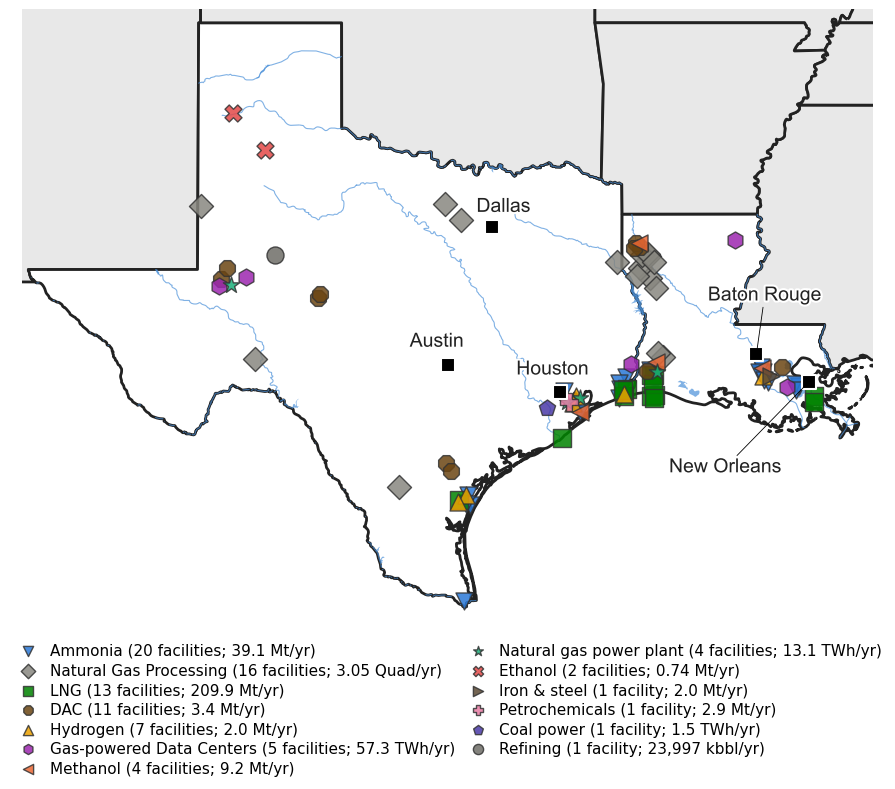

In [16]:
fig, ax = plot_facility_map(
    scenarios_df=scenarios_df,
    projects_df=projects_df,
    us_states_gdf=us_gdf,
    states=["Texas", "Louisiana"],
    methane_scenario="edf20",
    scenario_filter="baseline",
    title="",  # CCS-linked facilities: Texas and Louisiana",
    figsize=(14, 8),
    output_path=None,
    rivers_gdf=waterways_gdf,
    markers=INDUSTRY_MARKERS,
    # lakes_gdf=main_lakes_gdf,
)
fig.savefig(FIG_DIR / "fig1.png", dpi=600, bbox_inches="tight")
plt.show()

### Info to check figure 1 legend

In [17]:
projects_df[["product_amount", "co2_source"]].groupby("co2_source").sum()

,product_amount
co2_source,
ammonia,3.913432e+07
dac,3.367000e+06
ethanol,7.409940e+05
hydrogen,2.030128e+06
iron_steel,2.000000e+06
lng,2.099000e+08
methanol,9.250000e+06
ngp,3.052009e+09
petrochemicals,2.922000e+06


### Figure 2. Methane (CH₄) and carbon dioxide (CO₂) emissions from a generic industrial process coupled to CCS

_Diagram made in Google Slides — no code._

### Figure 3. Sources of annual greenhouse gas emissions from the buildout, while CCS is operational, by scenario (GWP20)

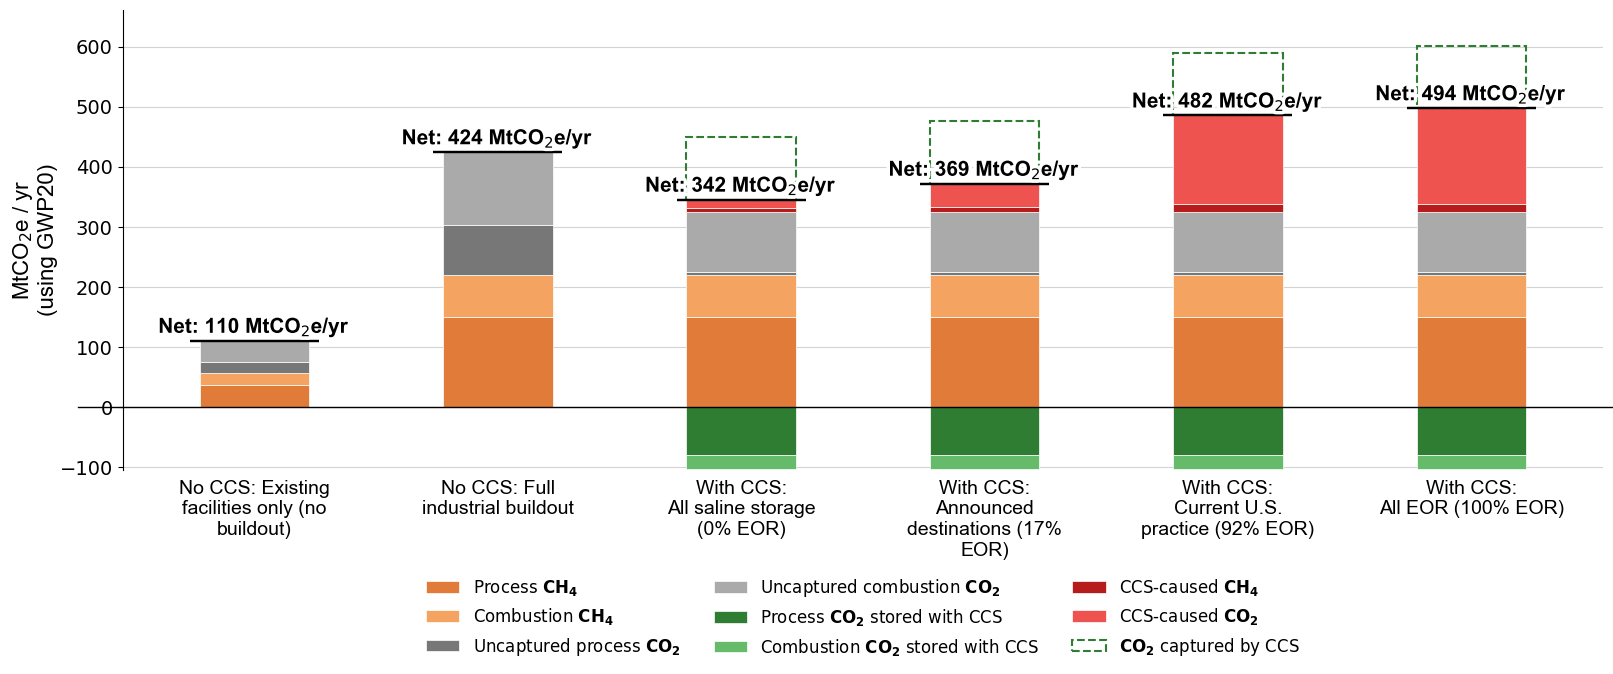

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(16, 7))
plot_state_emissions_vs_unabated_and_existing(
    industrial_emissions_df,
    ccs_emissions_df,
    scenarios_df,
    methane_scenario="edf20",
    destination_scenarios=[
        "existing",
        "unabated",
        "all_gs",
        "baseline",
        "current_mix",
        "all_eor",
    ],
    states=["TX", "LA"],
    # title="Gulf coast total emissions by scenario",
    title="",
    ax=ax,
    scenario_labels={  # overrides the x-tick labels per scenario
        "existing": "No CCS: Existing facilities only (no buildout)",
        "unabated": "No CCS: Full industrial buildout",
        "all_gs": "With CCS:\nAll saline storage (0% EOR)",
        "baseline": "With CCS:\nAnnounced destinations (17% EOR)",
        "current_mix": "With CCS:\nCurrent U.S. practice (92% EOR)",
        "all_eor": "With CCS:\nAll EOR (100% EOR)",
    },
    show_per_tco2_label=False,
)
ax.set_ylabel(ax.get_ylabel() + "\n(using GWP20)")
fig.savefig(FIG_DIR / "fig3.png", dpi=600, bbox_inches="tight")

### Figure 4. Share of each industry's emissions captured by CCS (Panel (a)) and net emissions change per tonne of CO₂ stored (Panel (b))

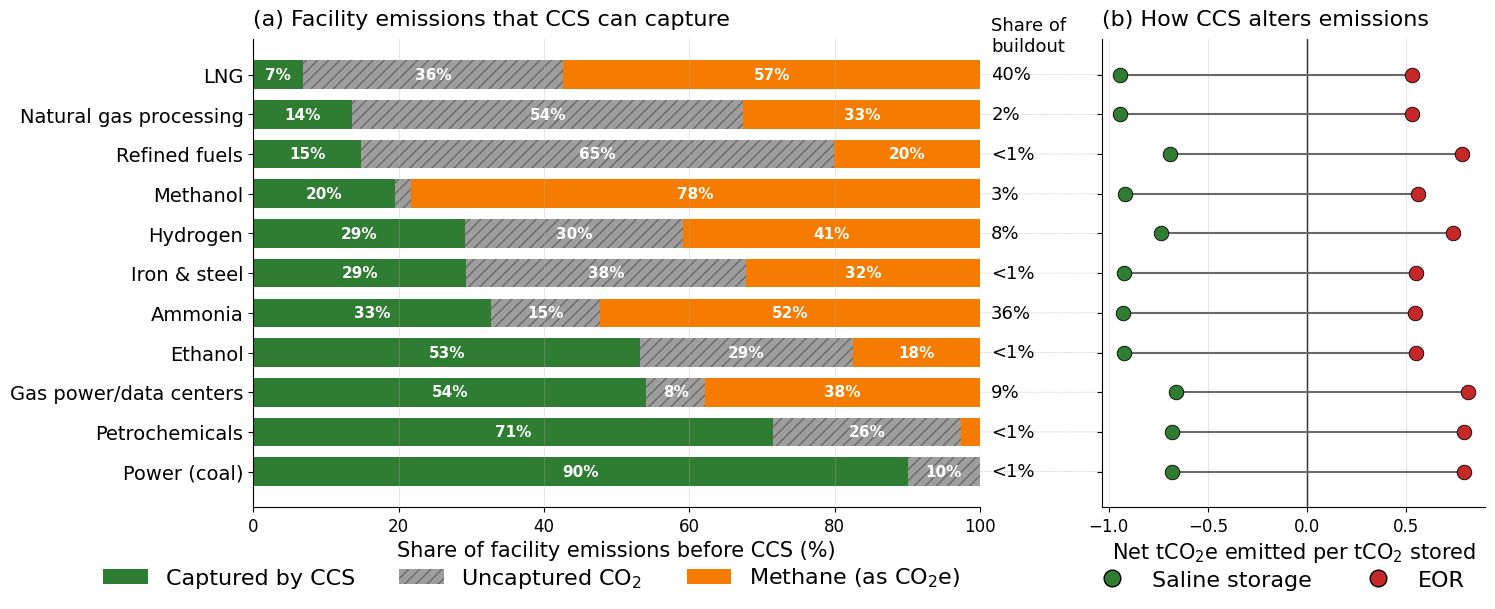

In [19]:
panel_a, panel_b = _compute_panel_data(
    industrial_emissions_df,
    ccs_emissions_df,
    scenarios_df,
    methane_scenario="edf20",  # 2.3% leak, GWP20
    industries=list(_DEFAULT_INDUSTRIES),
    states=("TX", "LA"),
)

fig, (ax_a, ax_b) = plot_two_panel(
    panel_a,
    panel_b,
    name_replacements=_NAME_REPLACEMENTS,
    figsize=(16, 6),
)
fig.savefig(FIG_DIR / "fig4.png", dpi=600, bbox_inches="tight")

### Figure 5. Emissions from the Gulf Coast buildout over time, with CCS stopping after the 45Q credit period (a, b) or continuing with all captured CO₂ sent to EOR (c, d)

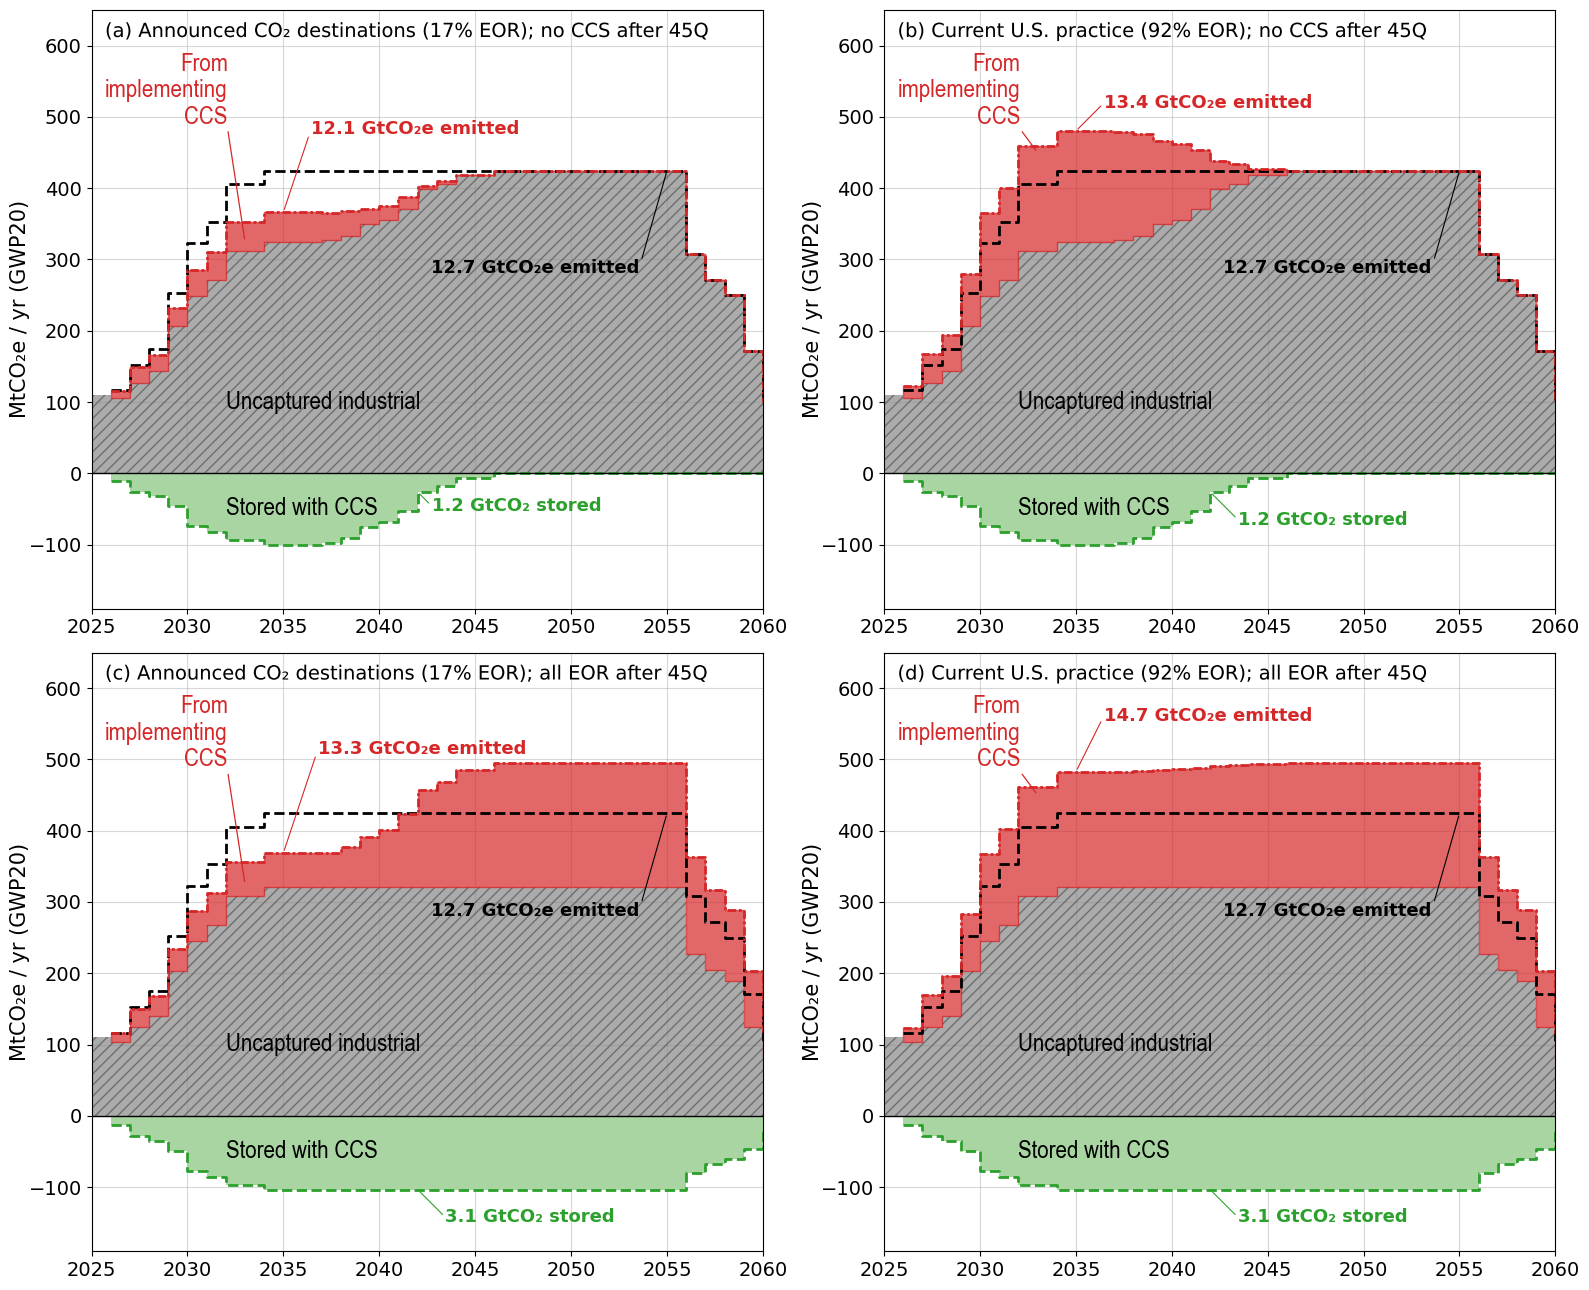

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.flatten()
start_year, end_year = 2025, 2060
ylim = (-190, 650)


panels = [
    {
        "scenario": "baseline",
        "label": "(a) Announced CO₂ destinations (17% EOR); no CCS after 45Q",
        "implementing_ccs_label_xy": (2025.7, 590),
        "implementing_ccs_anchor_xy": (2033, 325),
        "totals_offsets": {
            "net": (20, 60),
            "unabated": (-20, -70),
            "stored": (10, -10),
        },
    },
    {
        "scenario": "current_mix",
        "label": "(b) Current U.S. practice (92% EOR); no CCS after 45Q",
        "implementing_ccs_label_xy": (2025.7, 590),
        "implementing_ccs_anchor_xy": (2033, 450),
        "totals_offsets": {
            "net": (20, 20),
            "unabated": (-20, -70),
            "stored": (20, -20),
        },
    },
    {
        "scenario": "switching",
        "label": "(c) Announced CO₂ destinations (17% EOR); all EOR after 45Q",
        "implementing_ccs_label_xy": (2025.7, 590),
        "implementing_ccs_anchor_xy": (2033, 325),
        "totals_offsets": {
            "net": (25, 75),
            "unabated": (-20, -70),
            "stored": (20, -20),
        },
    },
    {
        "scenario": "switching_from_current",
        "label": "(d) Current U.S. practice (92% EOR); all EOR after 45Q",
        "implementing_ccs_label_xy": (2025.7, 590),
        "implementing_ccs_anchor_xy": (2033, 450),
        "totals_offsets": {
            "net": (20, 40),
            "unabated": (-20, -70),
            "stored": (20, -20),
        },
    },
]

for ax, cfg in zip(axes, panels):
    plot_emissions_through_time(
        scenarios_df=scenarios_df,
        projects_df=projects_df,
        methane_scenario="edf20",
        scenario=cfg["scenario"],
        ccs_active_years=12,
        facility_lifetime_years=30,
        xlim=(start_year, end_year),
        ylim=ylim,
        ax=ax,
        display_mode="presentation",
        title="",
        title_fontsize=16,
        legend_fontsize=12,
        legend_ncol=2,
        plot_existing=True,
        label_totals=True,
        totals_anchor_years={"unabated": 2055, "net": 2035, "stored": 2042},
        totals_offsets=cfg["totals_offsets"],
        totals_fontsize=13,
        totals_fontweight="semibold",
        implementing_ccs_anchor_xy=cfg["implementing_ccs_anchor_xy"],
        implementing_ccs_label_xy=cfg["implementing_ccs_label_xy"],
    )
    ax.text(
        0.02,
        0.98,
        cfg["label"],
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="normal",
        path_effects=[pe.withStroke(linewidth=1, foreground="w", alpha=0.9)],
    )
    ax.plot([start_year, end_year], [0, 0], lw=1, color="black")
    ax.set_axisbelow(True)
    ax.set_xlabel("")
    ax.set_ylabel(ax.get_ylabel() + " (GWP20)", fontsize=15)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig5.png", dpi=600, bbox_inches="tight")

### Figure 6. Net lifetime emissions from all Gulf Coast facilities in the dataset versus supply-chain methane leak rate, under GWP20 (solid) and GWP100 (dashed)

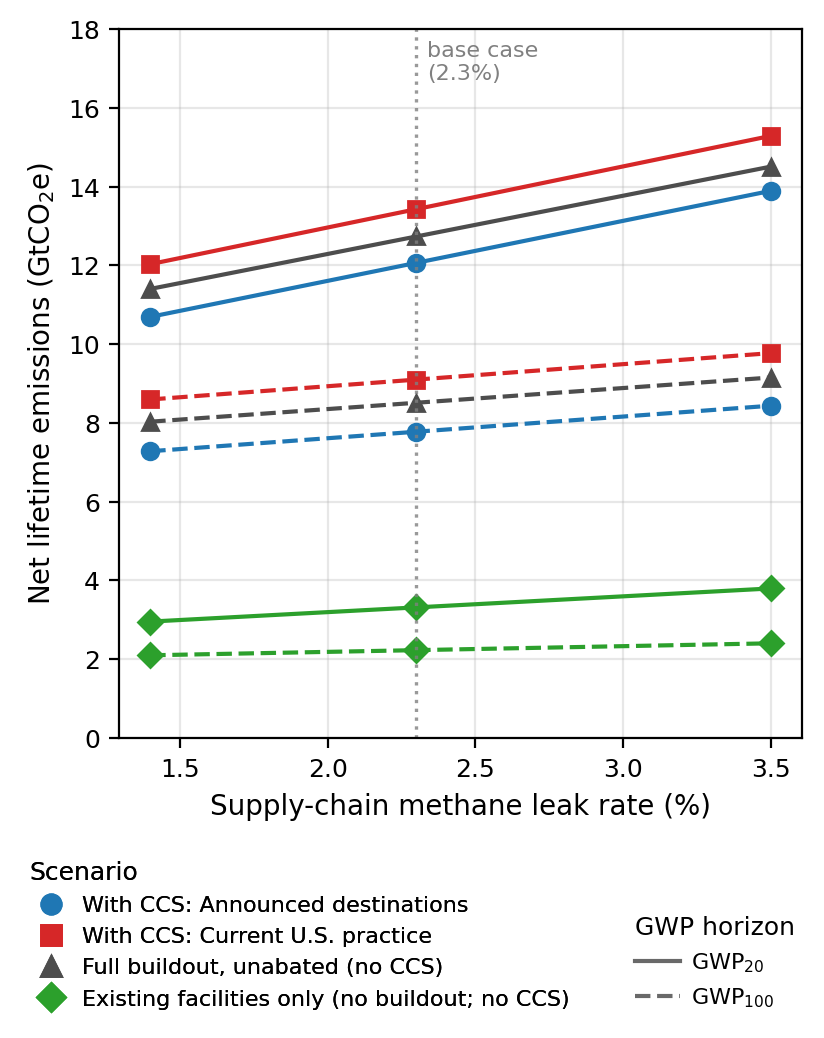

In [21]:
agg = compute_buildout_lifetime(
    scenarios_df,
    methane_scenarios=[
        "industry_cited_gwp100",
        "edf100",
        "leak3pt5_gwp100",
        "industry_cited_gwp20",
        "edf20",
        "leak3pt5_gwp20",
    ],
    destination_scenarios=[
        "baseline",
        "current_mix",
    ],
    states=("TX", "LA"),
)
fig, _ = plot_lifetime_emissions_vs_leak_rate(
    agg,
    scenario_labels={
        "baseline": "With CCS: Announced destinations",
        "current_mix": "With CCS: Current U.S. practice",
        "all_eor": "With CCS: All EOR",
        "all_gs": "With CCS: All saline storage",
    },
    destination_scenarios=["baseline", "current_mix"],
)
fig.set_dpi(200)  # high-res on-screen render
fig.savefig(FIG_DIR / "fig6.png", dpi=600, bbox_inches="tight");

### Figure 7. Net lifetime emissions of the Texas and Louisiana buildout versus the present value of oil producers' profit from EOR oil, by scenario

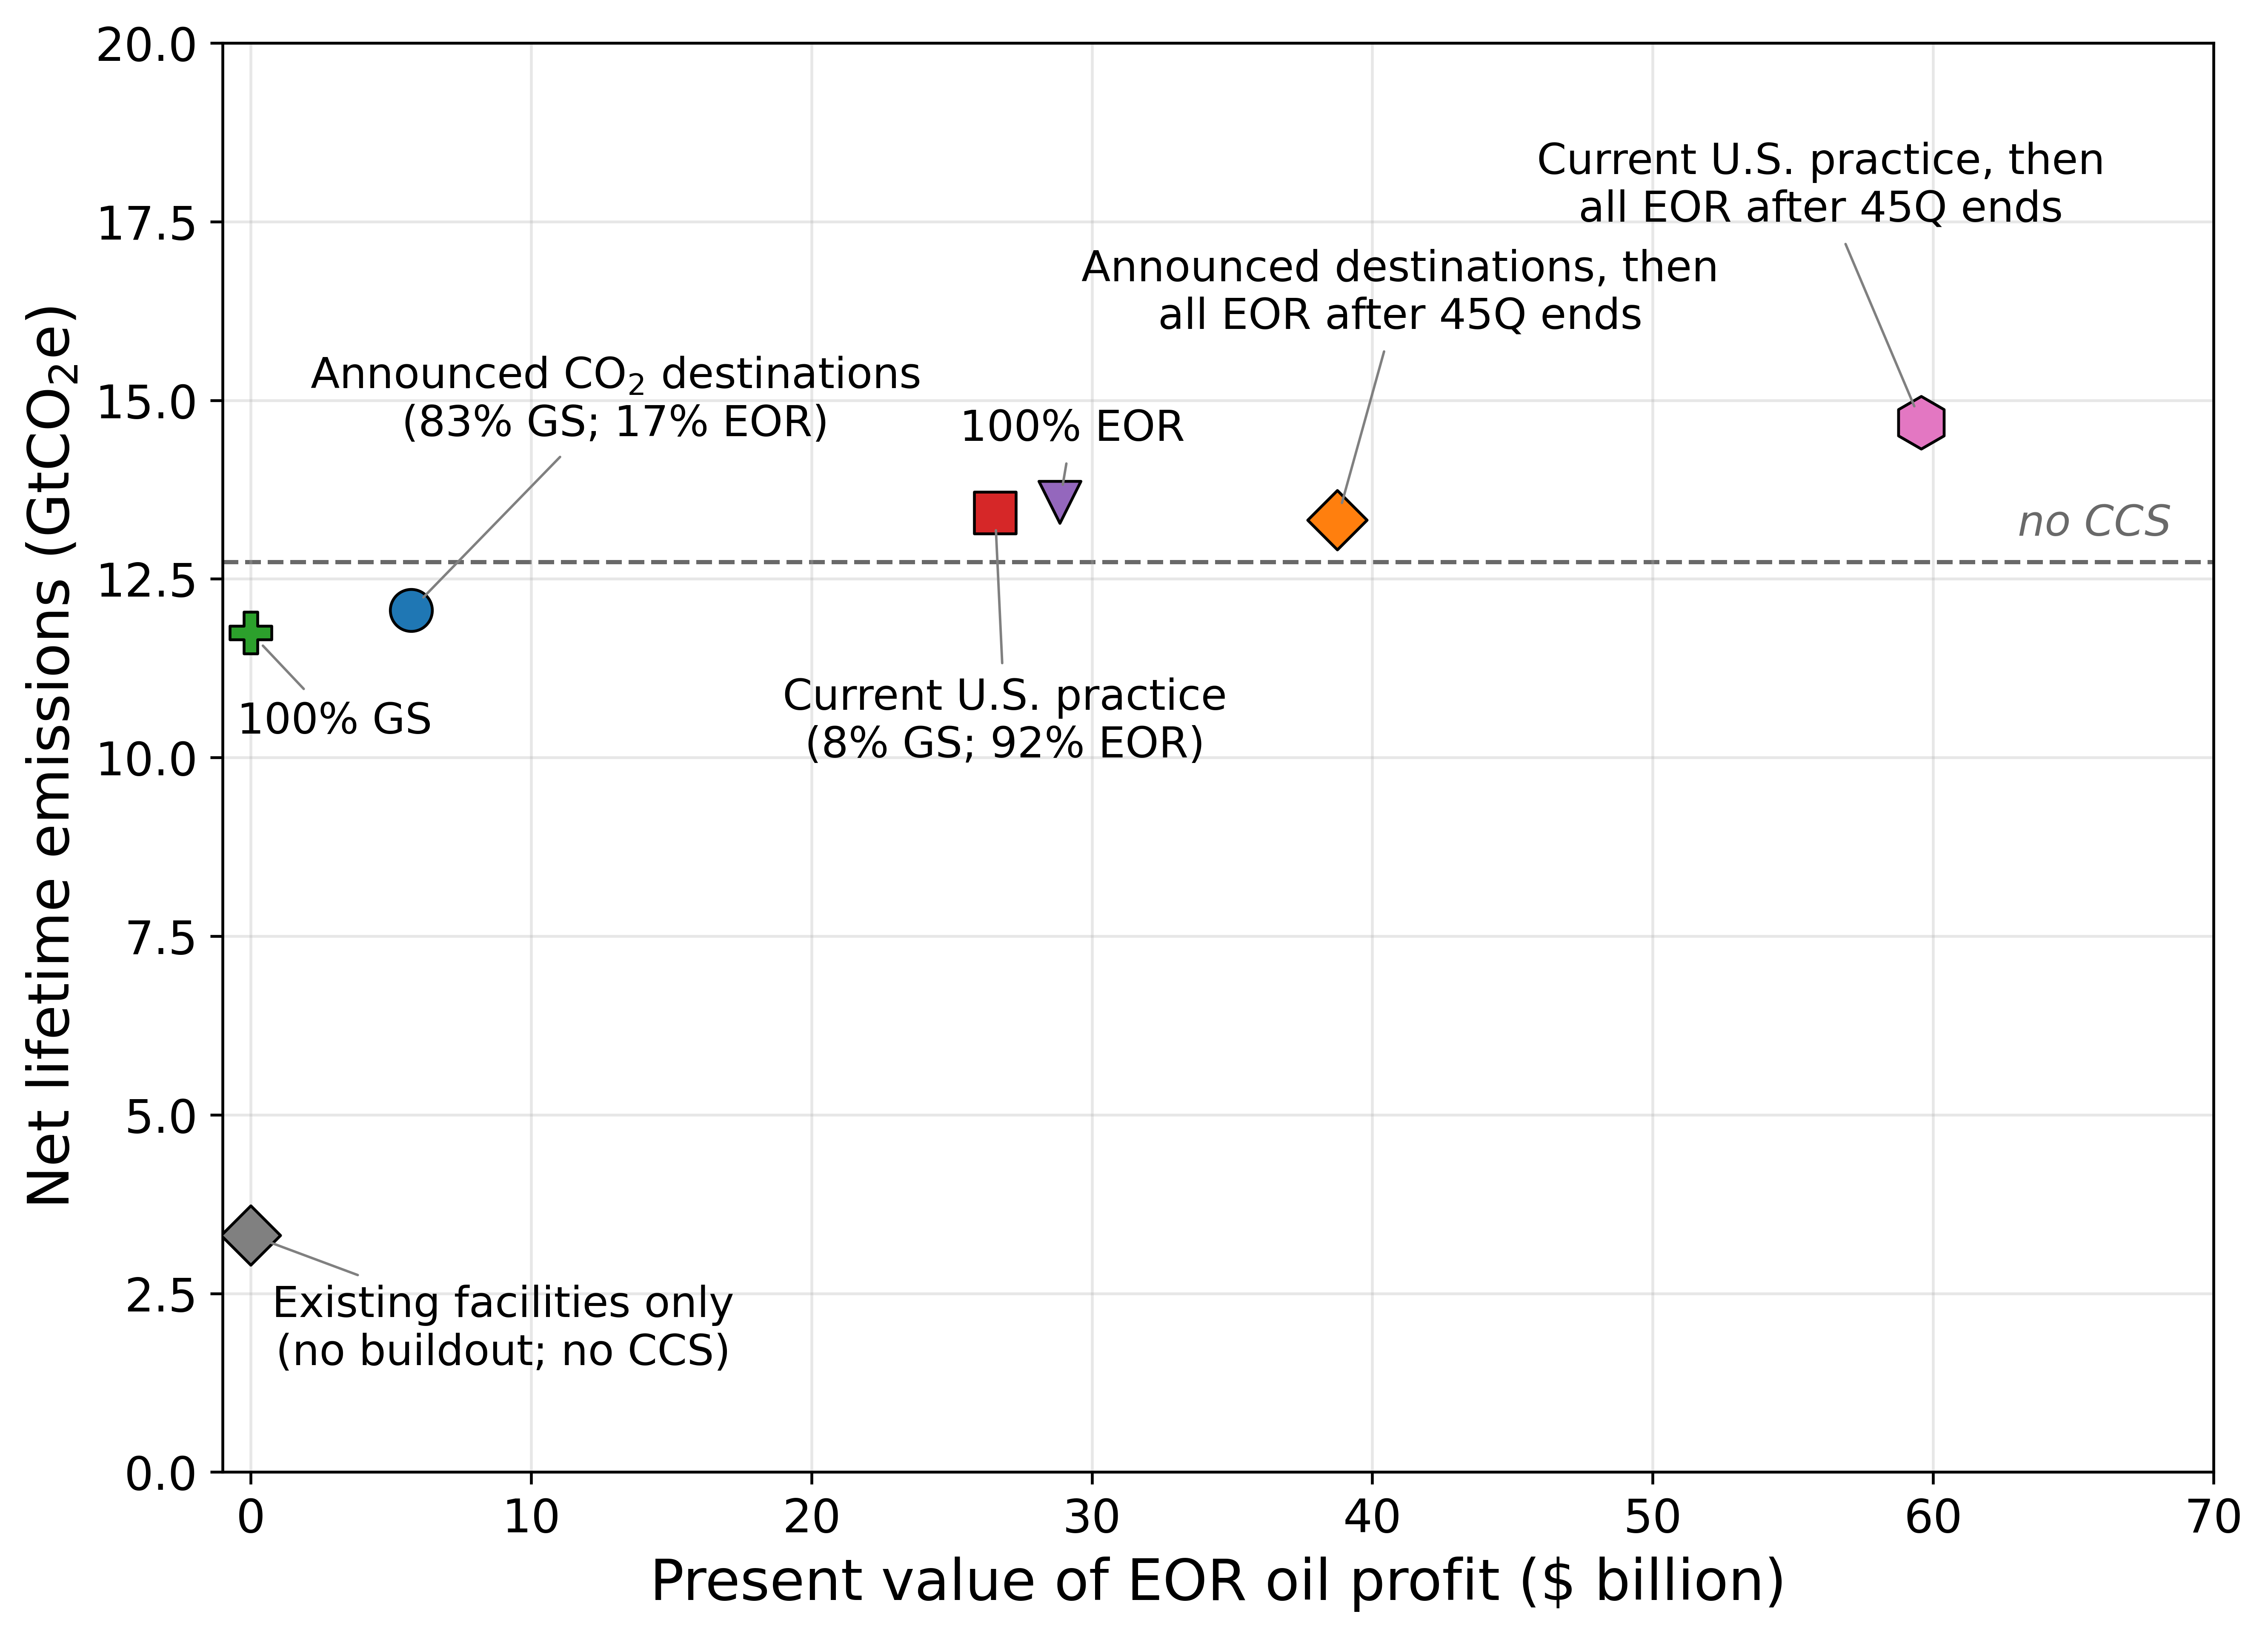

In [22]:
_METHANE_SCEN = "edf20"
_DEST_SCENS = [
    "all_gs",
    "baseline",
    "current_mix",
    "all_eor",
    "switching",
    "switching_from_current",
]
_STATES = ("TX", "LA")

ccs_df = compute_scenario_totals(
    scenarios_df,
    methane_scenario=_METHANE_SCEN,
    destination_scenarios=_DEST_SCENS,
    states=_STATES,
)
cf_df = compute_counterfactual_totals(scenarios_df, _METHANE_SCEN, _STATES)
profit_df = pd.concat([ccs_df, cf_df], ignore_index=True)

fig, _ = plot_profit_vs_emissions(profit_df)
fig.set_dpi(600)  # high-res on-screen render
fig.savefig(FIG_DIR / "fig7.png", dpi=600, bbox_inches="tight");

### Figure 8. Change in lifetime greenhouse gas emissions of the Texas and Louisiana buildout relative to the unabated buildout (no CCS), by CO₂-destination scenario and for an equivalent solar purchase, with methane expressed using GWP20 (dark) and GWP100 (light)

In [23]:
fig = plot_lifetime_delta_vs_unabated(
    scenarios_df,
    gwp_horizons=(20, 100),
    scenario_labels={
        "all_gs": "With CCS: All\nsaline storage\n(0% EOR);\nno CCS after 45Q",
        "baseline": "With CCS:\nAnnounced\ndestinations\n(17% EOR);\nno CCS after 45Q",
        "current_mix": "With CCS: Current\nU.S. practice\n(92% EOR);\nno CCS after 45Q",
        "all_eor": "With CCS:\nAll EOR\n(100% EOR);\nno CCS after 45Q",
        "switching": "Pivot to EOR:\nAnnounced\ndestinations\n(17% EOR)\n→ 100% EOR\nafter 45Q",
        "switching_from_current": "Pivot to EOR:\nCurrent practice;\n→ 100% EOR\nafter 45Q",
        "equivalent_solar": "Equivalent solar\n(45Q dollars\n→ utility PV)",
    },
    savepath=str(FIG_DIR / "fig8.png"),
)
fig.set_dpi(600)

### Figure S1. Sources of annual greenhouse gas emissions from the buildout, while CCS is operational, by scenario (GWP100)

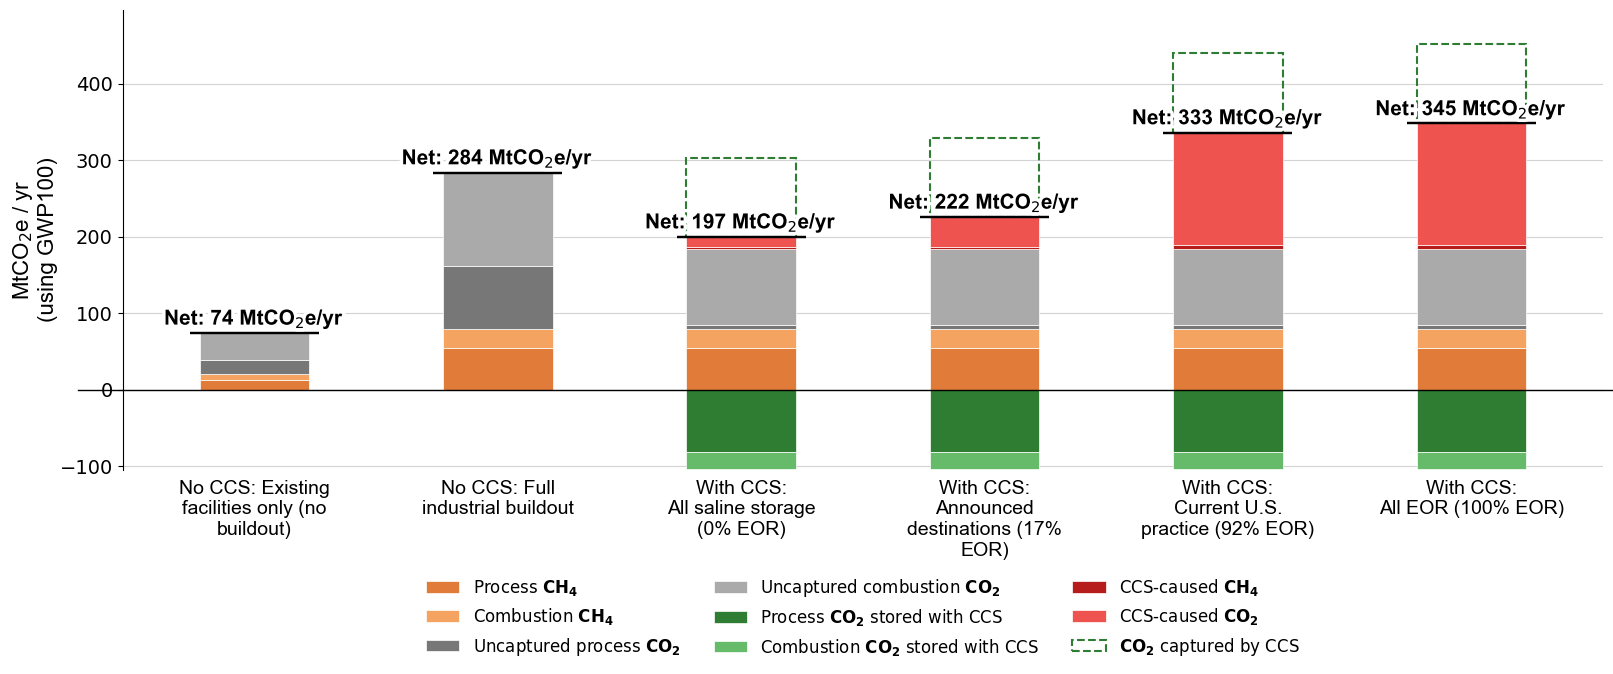

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(16, 7))
plot_state_emissions_vs_unabated_and_existing(
    industrial_emissions_df,
    ccs_emissions_df,
    scenarios_df,
    methane_scenario="edf100",
    destination_scenarios=[
        "existing",
        "unabated",
        "all_gs",
        "baseline",
        "current_mix",
        "all_eor",
    ],
    states=["TX", "LA"],
    # title="Gulf coast total emissions by scenario",
    title="",
    ax=ax,
    scenario_labels={  # overrides the x-tick labels per scenario
        "existing": "No CCS: Existing facilities only (no buildout)",
        "unabated": "No CCS: Full industrial buildout",
        "all_gs": "With CCS:\nAll saline storage (0% EOR)",
        "baseline": "With CCS:\nAnnounced destinations (17% EOR)",
        "current_mix": "With CCS:\nCurrent U.S. practice (92% EOR)",
        "all_eor": "With CCS:\nAll EOR (100% EOR)",
    },
    show_per_tco2_label=False,
)
ax.set_ylabel(ax.get_ylabel() + "\n(using GWP100)")
fig.savefig(FIG_DIR / "figs1.png", dpi=600, bbox_inches="tight")

### Figure S2. Share of each industry's emissions captured by CCS (Panel (a)) and net emissions change per tonne of CO₂ stored (Panel (b)), using GWP100

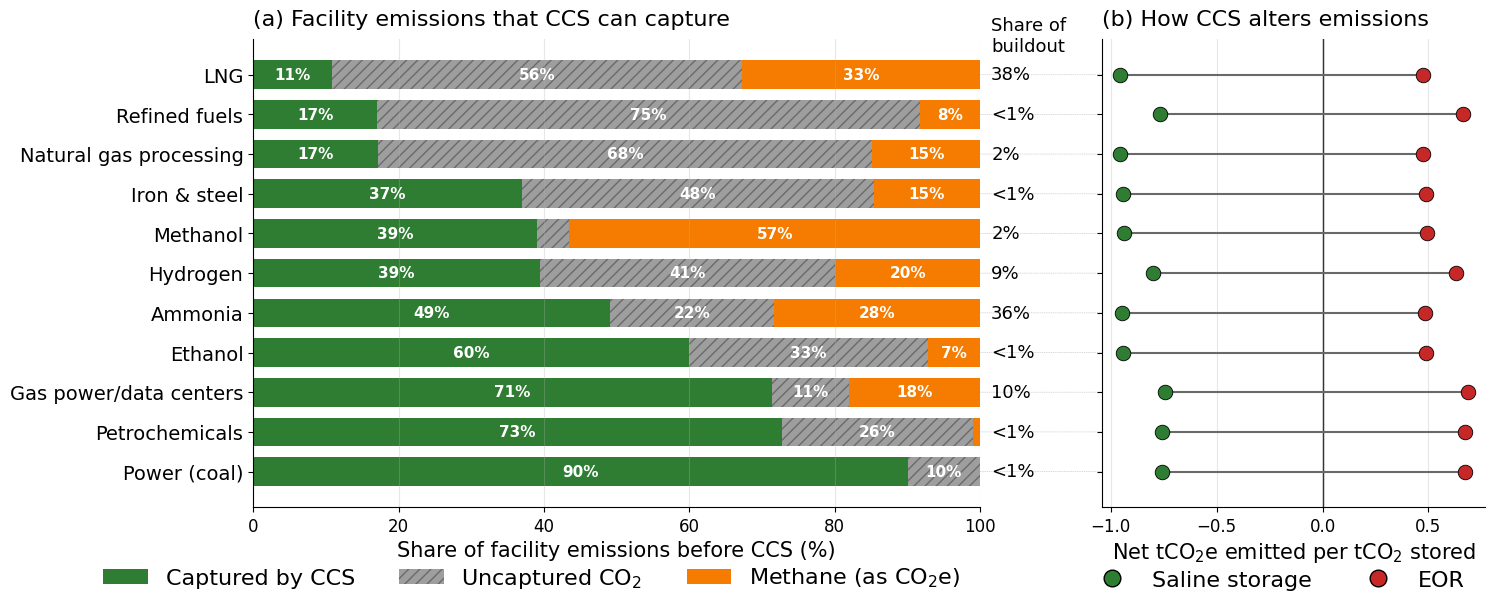

In [25]:
panel_a, panel_b = _compute_panel_data(
    industrial_emissions_df,
    ccs_emissions_df,
    scenarios_df,
    methane_scenario="edf100",  # 2.3% leak, GWP20
    industries=list(_DEFAULT_INDUSTRIES),
    states=("TX", "LA"),
)

fig, (ax_a, ax_b) = plot_two_panel(
    panel_a,
    panel_b,
    name_replacements=_NAME_REPLACEMENTS,
    figsize=(16, 6),
)
fig.savefig(FIG_DIR / "figs2.png", dpi=600, bbox_inches="tight")

### Figure S3. Annual greenhouse gas emissions from the Texas and Louisiana buildout over time, as in Figure 5, using GWP100

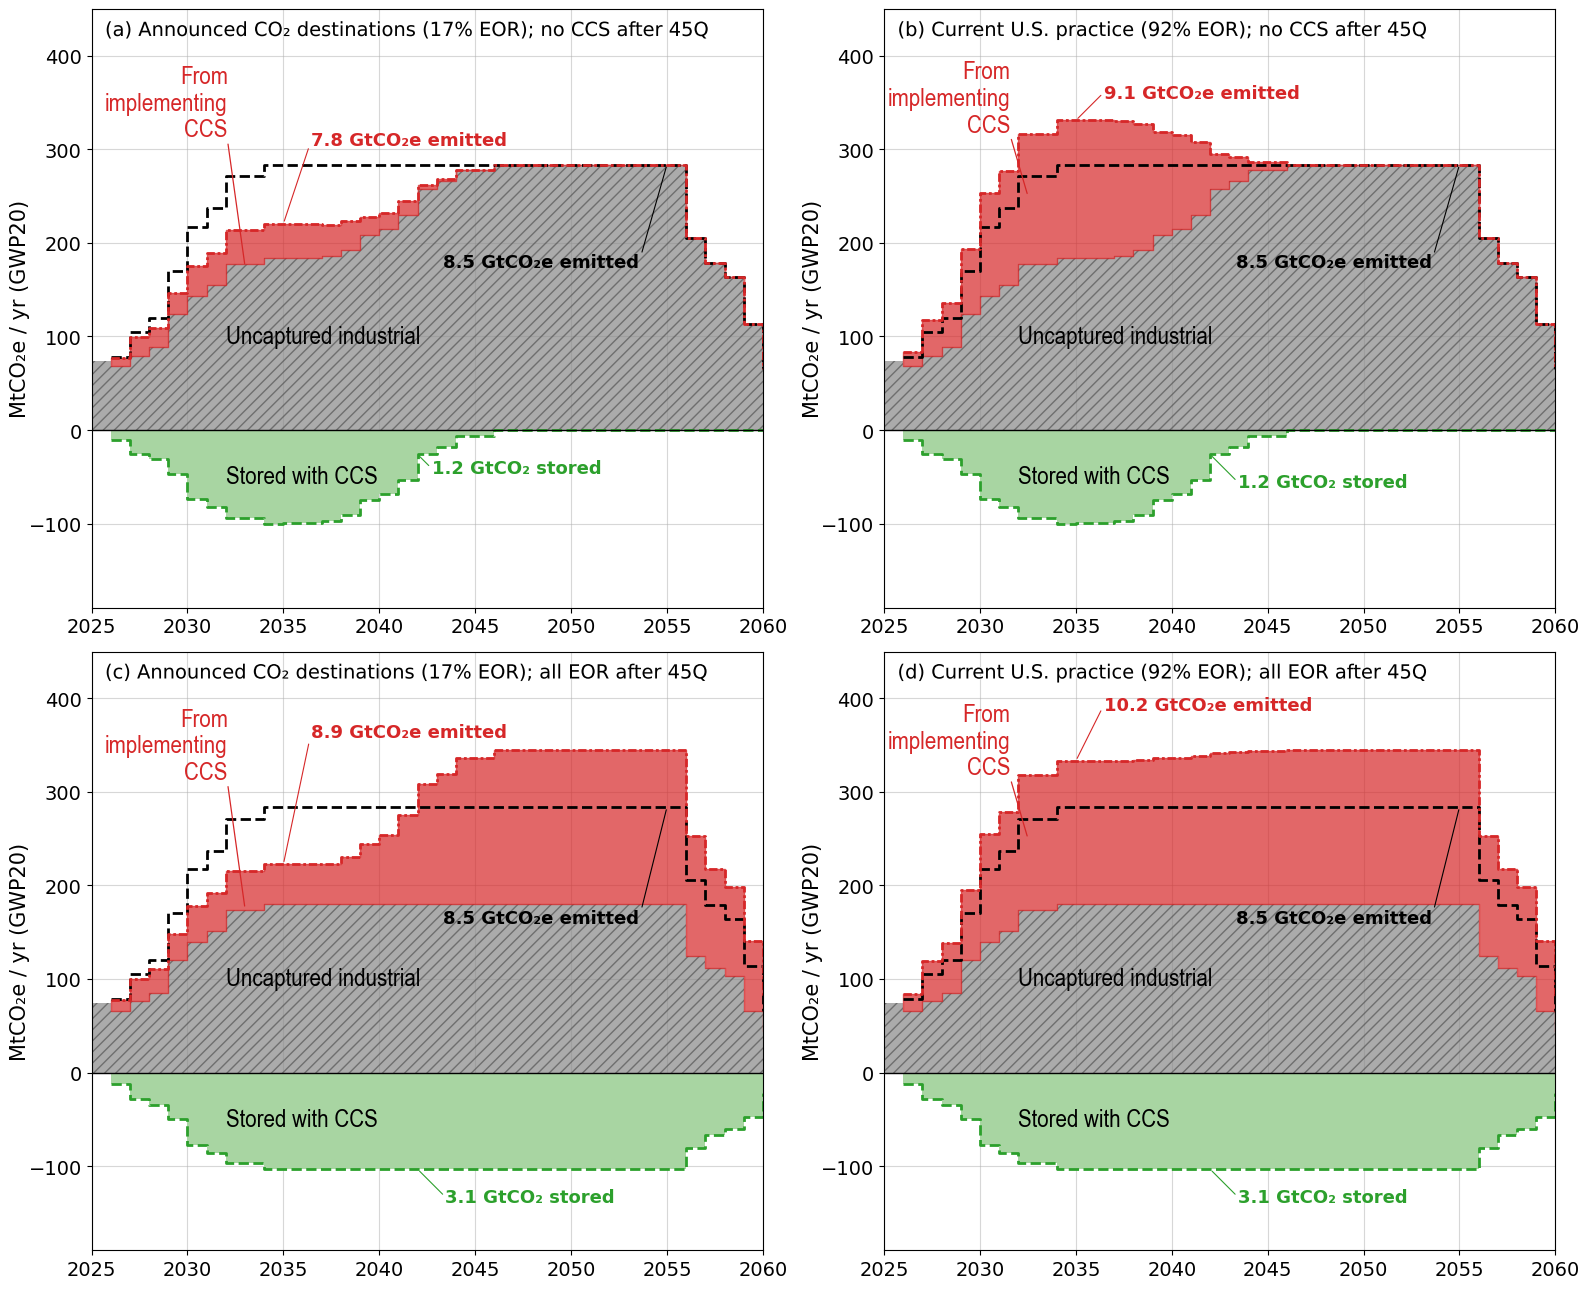

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.flatten()
start_year, end_year = 2025, 2060
ylim = (-190, 450)


panels = [
    {
        "scenario": "baseline",
        "label": "(a) Announced CO₂ destinations (17% EOR); no CCS after 45Q",
        "implementing_ccs_label_xy": (2025.7, 390),
        "implementing_ccs_anchor_xy": (2033, 175),
        "totals_offsets": {
            "net": (20, 60),
            "unabated": (-20, -70),
            "stored": (10, -10),
        },
    },
    {
        "scenario": "current_mix",
        "label": "(b) Current U.S. practice (92% EOR); no CCS after 45Q",
        "implementing_ccs_label_xy": (2025.2, 395),
        "implementing_ccs_anchor_xy": (2032.5, 250),
        "totals_offsets": {
            "net": (20, 20),
            "unabated": (-20, -70),
            "stored": (20, -20),
        },
    },
    {
        "scenario": "switching",
        "label": "(c) Announced CO₂ destinations (17% EOR); all EOR after 45Q",
        "implementing_ccs_label_xy": (2025.7, 390),
        "implementing_ccs_anchor_xy": (2033, 175),
        "totals_offsets": {
            "net": (20, 95),
            "unabated": (-20, -80),
            "stored": (20, -20),
        },
    },
    {
        "scenario": "switching_from_current",
        "label": "(d) Current U.S. practice (92% EOR); all EOR after 45Q",
        "implementing_ccs_label_xy": (2025.2, 395),
        "implementing_ccs_anchor_xy": (2032.5, 250),
        "totals_offsets": {
            "net": (20, 40),
            "unabated": (-20, -80),
            "stored": (20, -20),
        },
    },
]

for ax, cfg in zip(axes, panels):
    plot_emissions_through_time(
        scenarios_df=scenarios_df,
        projects_df=projects_df,
        methane_scenario="edf100",
        scenario=cfg["scenario"],
        ccs_active_years=12,
        facility_lifetime_years=30,
        xlim=(start_year, end_year),
        ylim=ylim,
        ax=ax,
        display_mode="presentation",
        title="",
        title_fontsize=16,
        legend_fontsize=12,
        legend_ncol=2,
        plot_existing=True,
        label_totals=True,
        totals_anchor_years={"unabated": 2055, "net": 2035, "stored": 2042},
        totals_offsets=cfg["totals_offsets"],
        totals_fontsize=13,
        totals_fontweight="semibold",
        implementing_ccs_anchor_xy=cfg["implementing_ccs_anchor_xy"],
        implementing_ccs_label_xy=cfg["implementing_ccs_label_xy"],
    )
    ax.text(
        0.02,
        0.98,
        cfg["label"],
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="normal",
        path_effects=[pe.withStroke(linewidth=1, foreground="w", alpha=0.9)],
    )
    ax.plot([start_year, end_year], [0, 0], lw=1, color="black")
    ax.set_axisbelow(True)
    ax.set_xlabel("")
    ax.set_ylabel(ax.get_ylabel() + " (GWP20)", fontsize=15)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)

fig.tight_layout()
fig.savefig(FIG_DIR / "figs3.png", dpi=600, bbox_inches="tight")

### Figure S4. Relative proportions of climate-warming emissions streams from a hydrogen production facility that are captured and emitted to the atmosphere

In [27]:
### Hydrogen sankey diagram
fig = plot_industry_sankey(
    industrial_emissions_df=industrial_emissions_df,
    industry="hydrogen",
    methane_scenario="edf20",
    minimal_labels=True,
    display_mode="report",
    show_final_values=True,
    # capture_fraction=0.99,
    # which_flavor: Optional[str] = None,
    # title: Optional[str] = None,
    width=1000,
    # height=620,
    # output_path: Optional[str] = None,
)
fig.write_image(str(FIG_DIR / "figs4.png"), scale=4)

### Figure S5. U.S. Gulf Coast total carbon-emissions flows after full 86-project industrial buildout with CCS

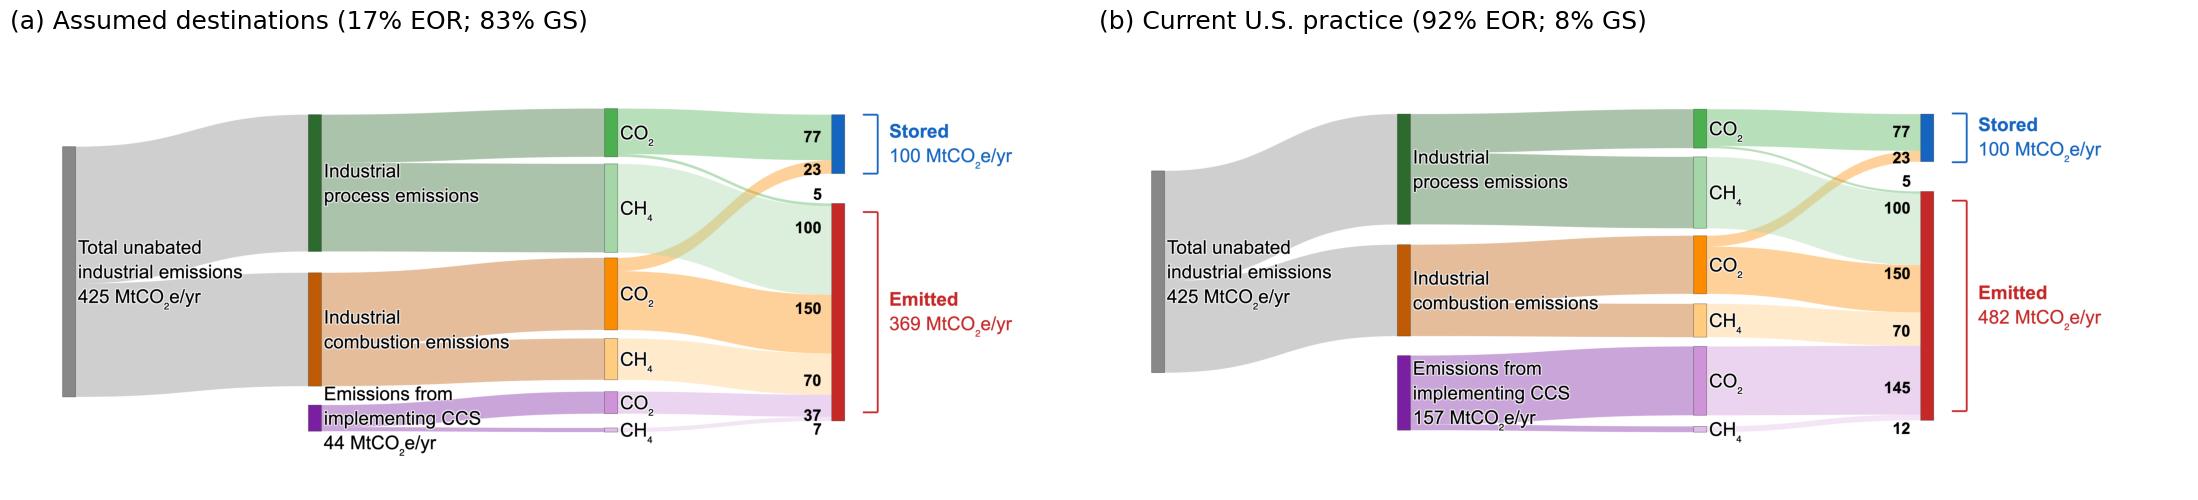

In [28]:
# ─── 1. Render each sankey to its own PNG via plot_state_sankey's native kaleido export.
_tmp_dir = Path("/tmp")
_png_a = Path("/tmp/_sankey_panel_a.png")
_png_b = Path("/tmp/_sankey_panel_b.png")

for eor_pct, out_path in [(20, _png_a), (96.5, _png_b)]:
    fig = plot_state_sankey(
        industrial_emissions_df,
        ccs_emissions_df,
        scenarios_df,
        methane_scenario="edf20",
        min_label=True,
        eor_pct=eor_pct,
        display_mode="presentation",
        show_final_values=True,
        title="",
        output_path=None,  # don't write yet — we need to override margin first
    )
    fig.update_layout(margin={"r": 60})  # was 200 — trims ~140 px of right whitespace
    fig.write_image(str(out_path), scale=3)

# ─── 2. Assemble the two PNGs into a 1x2 matplotlib figure with panel titles.
img_a = mpimg.imread(_png_a)
img_b = mpimg.imread(_png_b)

fig, axes = plt.subplots(1, 2, figsize=(22, 7))
panels = (
    (img_a, "(a) Assumed destinations (17% EOR; 83% GS)"),
    (img_b, "(b) Current U.S. practice (92% EOR; 8% GS)"),
)
for ax, (img, label) in zip(axes, panels):
    ax.imshow(img)
    ax.set_title(label, fontsize=18, fontweight="normal", loc="left", pad=8)
    ax.axis("off")

fig.subplots_adjust(wspace=0.00, left=0.005, right=0.995, top=0.995, bottom=0.01)
fig.savefig(FIG_DIR / "figs5.png", dpi=600, bbox_inches="tight")
plt.show()

In [29]:
summary_df = build_multi_scenario_summary(
    scenarios_df,
    industrial_emissions_df,
    ccs_emissions_df,
    methane_scenarios=["edf20", "edf100"],
)
summary_df.to_clipboard()

## Tables

### Table 1 (partial). Industry-specific emissions, capture fractions, and CCS emissions factors

In [30]:
_PRETTY_NAME = {
    "hydrogen": "Hydrogen (ton H2)",
    "ammonia": "Ammonia (ton NH3)",
    "methanol": "Methanol (ton MeOH)",
    "ethanol": "Ethanol (ton EtOH)",
    "lng": "LNG (ton LNG)",
    "ngp": "Natural gas processing (MMBtu)",
    "power_ng_retrofit": "Natural gas power, retrofit (MWh)*",
    "power_ng_new_build": "Natural gas power, new build (MWh)*",
    "power_coal": "Coal power, retrofit (MWh)*",
    "refined_fuels": "Refined fuels (bbl/yr)",
    "petrochemicals": "Petrochemicals (ton C2H4)",
    "iron_steel": "Iron & steel (ton DRI)",
    "dac": "DAC (ton CO2)",
}
_ROW_ORDER = list(_PRETTY_NAME.values())

# --- effective capture fractions (per-industry means) ------------------------
_keep = industrial_emissions_df["industrial_product"] != (
    "natural gas processing -- high CO2 gas"
)

acf_gwp20 = (
    industrial_emissions_df.loc[
        _keep & (industrial_emissions_df["methane_scenario"] == "edf20"),
        [
            "simple_product_name",
            "adjusted_capture_fraction_tco2",
            "adjusted_capture_fraction_tco2e",
        ],
    ]
    .groupby("simple_product_name", as_index=False)
    .mean()
    .rename(
        columns={
            "adjusted_capture_fraction_tco2": "acf_co2",
            "adjusted_capture_fraction_tco2e": "acf_co2e_gwp20",
        }
    )
)
acf_gwp100 = (
    industrial_emissions_df.loc[
        _keep & (industrial_emissions_df["methane_scenario"] == "edf100"),
        ["simple_product_name", "adjusted_capture_fraction_tco2e"],
    ]
    .groupby("simple_product_name", as_index=False)
    .mean()
    .rename(columns={"adjusted_capture_fraction_tco2e": "acf_co2e_gwp100"})
)


# --- lifecycle emission factors ε̄_{i,d} per industry -------------------------
def _ef_by_industry(scenario_id: str, out_name: str) -> pd.DataFrame:
    return (
        scenarios_df.loc[scenarios_df["scenario_id"] == scenario_id]
        .groupby("product", as_index=False)["tco2e_emitted_per_tco2_ccs"]
        .mean()
        .rename(
            columns={
                "product": "simple_product_name",
                "tco2e_emitted_per_tco2_ccs": out_name,
            }
        )
    )


ef_table_df = (
    acf_gwp20.merge(acf_gwp100, on="simple_product_name", how="outer")
    .merge(
        _ef_by_industry("all_gs-edf20", "ef_gs_gwp20"),
        on="simple_product_name",
        how="left",
    )
    .merge(
        _ef_by_industry("all_eor-edf20", "ef_eor_gwp20"),
        on="simple_product_name",
        how="left",
    )
    .merge(
        _ef_by_industry("all_gs-edf100", "ef_gs_gwp100"),
        on="simple_product_name",
        how="left",
    )
    .merge(
        _ef_by_industry("all_eor-edf100", "ef_eor_gwp100"),
        on="simple_product_name",
        how="left",
    )
)

# Apply pretty name + requested row order; drop industries not in the list
# (e.g., power_ng_data_center) and surface any that fell out so you notice.
_missing_from_pretty = sorted(
    set(ef_table_df["simple_product_name"]) - set(_PRETTY_NAME)
)
if _missing_from_pretty:
    print(f"[info] Dropped industries not in display list: {_missing_from_pretty}")

ef_table_df = (
    ef_table_df.assign(industry=ef_table_df["simple_product_name"].map(_PRETTY_NAME))
    .dropna(subset=["industry"])
    .assign(
        industry=lambda d: pd.Categorical(
            d["industry"], categories=_ROW_ORDER, ordered=True
        )
    )
    .sort_values("industry")[
        [
            "industry",
            "acf_co2",
            "acf_co2e_gwp20",
            "acf_co2e_gwp100",
            "ef_gs_gwp20",
            "ef_eor_gwp20",
            "ef_gs_gwp100",
            "ef_eor_gwp100",
        ]
    ]
    .reset_index(drop=True)
)
ef_table_df.to_clipboard()
ef_table_df

[info] Dropped industries not in display list: ['power_ng_data_center']


,industry,acf_co2,acf_co2e_gwp20,acf_co2e_gwp100,ef_gs_gwp20,ef_eor_gwp20,ef_gs_gwp100,ef_eor_gwp100
0,Hydrogen (ton H2),0.492888,0.291480,0.394439,0.257017,1.730984,0.197271,1.627923
1,Ammonia (ton NH3),0.686095,0.327005,0.491242,0.067505,1.541182,0.052691,1.483248
2,Methanol (ton MeOH),0.900000,0.195433,0.390925,0.082290,1.555764,0.063196,1.493687
3,Ethanol (ton EtOH),0.645139,0.534091,0.600070,0.066886,1.540968,0.054043,1.484733
4,LNG (ton LNG),0.161087,0.068682,0.108405,0.054709,1.528230,0.042170,1.472676
5,Natural gas processing (MMBtu),0.201724,0.136019,0.171755,0.053439,1.527014,0.041371,1.471894
6,"Natural gas power, retrofit (MWh)*",0.870000,0.540683,0.713111,NaN,NaN,NaN,NaN
7,"Natural gas power, new build (MWh)*",0.870000,0.540683,0.713111,0.329719,1.803598,0.253227,1.683850
8,"Coal power, retrofit (MWh)*",0.900000,0.900000,0.900000,0.309974,1.784056,0.239404,1.670094
9,Refined fuels (bbl/yr),0.186103,0.149467,0.170965,0.300009,1.774091,0.231352,1.662042


### Table 4. Annual unabated greenhouse gas emissions after full buildout, by industry and state

In [31]:
ng_products = [
    "power_ng_data_center",
    "ammonia",
    "ngp",
    "lng",
    "power_ng_new_build",
    "methanol",
    "hydrogen",
    "petrochemicals",
    "iron_steel",  # DRI uses natural gas as a reactant
]

base = scenarios_df.loc[
    (scenarios_df["methane_scenario"] == "edf20")
    & (scenarios_df["scenario"] == "baseline")
]

unabated_df = (
    base.groupby("product")["unabated_mtco2e_per_yr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
unabated = unabated_df["unabated_mtco2e_per_yr"].sum()
natural_gas_pct = (
    100
    * unabated_df.loc[
        unabated_df["product"].isin(ng_products), "unabated_mtco2e_per_yr"
    ].sum()
    / unabated
)
print(
    f"Natural gas products account for {natural_gas_pct:.1f}% of the total {unabated:.1f} MtCO2e per year of emissions caused by unabated facilities (in the baseline scenario with EDF methane assumptions)"
)

unabated_df["pct_gulf_total"] = (
    100
    * unabated_df["unabated_mtco2e_per_yr"]
    / unabated_df["unabated_mtco2e_per_yr"].sum()
)
texas_df = (
    base.loc[base["project_state"] == "TX"]
    .groupby("product")["unabated_mtco2e_per_yr"]
    .sum()
    .rename("tx")
    .reset_index()
)
texas_df["pct_tx_total"] = 100 * texas_df["tx"] / texas_df["tx"].sum()

louisiana_df = (
    base.loc[base["project_state"] == "LA"]
    .groupby("product")["unabated_mtco2e_per_yr"]
    .sum()
    .rename("la")
    .reset_index()
)
louisiana_df["pct_la_total"] = 100 * louisiana_df["la"] / louisiana_df["la"].sum()

unabated_df = (
    unabated_df.rename(columns={"unabated_mtco2e_per_yr": "total"})
    .merge(texas_df, on="product", how="left")
    .merge(louisiana_df, on="product", how="left")
    .fillna(0)
)
unabated_df["All projects (TX + LA) MtCO2/yr (% of Gulf total)"] = [
    f"{m:.1f} ({p:.0f}%)" if p > 1 else f"{m:.1f} (<1%)"
    for m, p in zip(unabated_df["total"], unabated_df["pct_gulf_total"])
]
unabated_df["Texas projects MtCO2/yr (% of Texas total)"] = [
    f"{m:.1f} ({p:.0f}%)" if p > 1 else f"{m:.1f} (<1%)"
    for m, p in zip(unabated_df["tx"], unabated_df["pct_tx_total"])
]
unabated_df["Louisiana projects MtCO2/yr (% of Louisiana total)"] = [
    f"{m:.1f} ({p:.0f}%)" if p > 1 else f"{m:.1f} (<1%)"
    for m, p in zip(unabated_df["la"], unabated_df["pct_la_total"])
]
unabated_df.to_clipboard()  # remove if running without a clipboard (server/container)
unabated_df

Natural gas products account for 99.1% of the total 424.4 MtCO2e per year of emissions caused by unabated facilities (in the baseline scenario with EDF methane assumptions)


,product,total,pct_gulf_total,tx,pct_tx_total,la,pct_la_total,All projects (TX + LA) MtCO2/yr (% of Gulf total),Texas projects MtCO2/yr (% of Texas total),Louisiana projects MtCO2/yr (% of Louisiana total)
0,lng,169.843685,40.015182,55.427787,27.109017,114.415898,52.010638,169.8 (40%),55.4 (27%),114.4 (52%)
1,ammonia,154.876076,36.488812,89.567654,43.806386,65.308423,29.687594,154.9 (36%),89.6 (44%),65.3 (30%)
2,hydrogen,34.312790,8.084095,31.787280,15.546750,2.525509,1.148034,34.3 (8%),31.8 (16%),2.5 (1%)
3,power_ng_data_center,31.118140,7.331436,15.000925,7.336759,16.117215,7.326488,31.1 (7%),15.0 (7%),16.1 (7%)
4,methanol,12.246787,2.885344,1.456375,0.712294,10.790413,4.905055,12.2 (3%),1.5 (<1%),10.8 (5%)
5,ngp,7.879595,1.856433,2.070910,1.012856,5.808685,2.640485,7.9 (2%),2.1 (1%),5.8 (3%)
6,power_ng_new_build,7.129292,1.679662,4.480276,2.191245,2.649016,1.204177,7.1 (2%),4.5 (2%),2.6 (1%)
7,iron_steel,2.370409,0.558469,0.000000,0.000000,2.370409,1.077530,2.4 (<1%),0.0 (<1%),2.4 (1%)
8,power_coal,1.550930,0.365399,1.550930,0.758540,0.000000,0.000000,1.6 (<1%),1.6 (<1%),0.0 (<1%)
9,ethanol,1.307445,0.308034,1.307445,0.639454,0.000000,0.000000,1.3 (<1%),1.3 (<1%),0.0 (<1%)


### Table 5. Lifetime and annual buildout emissions by scenario (GWP20) and change relative to the two counterfactuals

In [32]:
table5_df = table5_scenario_emissions(gwp=20, as_fraction=True)
table5_df.to_clipboard()
table5_df

,Scenario,"Annual (MtCO₂e/yr, GWP20)",Δ Annual vs. existing (MtCO₂e/yr),Δ Annual vs. unabated (fraction),"Lifetime (GtCO₂e, GWP20)",Δ Lifetime vs. existing (GtCO₂e),Δ Lifetime vs. unabated (fraction)
0,"Existing facilities only (no further buildout,...",110.486795,0.000000,-0.739693,3.314604,0.000000,-0.739693
1,"Full buildout, unabated (no CCS)",424.448116,313.961321,0.000000,12.733443,9.418840,0.000000
2,100% Geologic storage ('best case' climate imp...,342.130023,231.643227,-0.193941,11.745626,8.431023,-0.077577
3,"Announced destinations (17% EOR, 83% GS)",368.659798,258.173003,-0.131437,12.063984,8.749380,-0.052575
4,"Current U.S. practice (92% EOR, 8% GS)",482.280833,371.794038,0.136254,13.427436,10.112832,0.054502
5,100% EOR ('worst case' while 45Q is paid),494.467860,383.981065,0.164967,13.573680,10.259077,0.065987
6,"Announced destinations, then all EOR after 45Q",444.144635,333.657840,0.046405,13.324339,10.009735,0.046405
7,"Current U.S. practice, then all EOR after 45Q",489.593050,379.106254,0.153481,14.687791,11.373188,0.153481


### Table 6. EOR oil barrels produced, profit to oil companies, and net change in lifetime emissions

In [33]:
table6_df = scenario_oil_and_emissions_table()
table6_df.to_clipboard()
table6_df

,Scenario,EOR oil produced (billion bbl),"Profit, nominal ($ billion)","Profit, present value ($ billion)","Change in lifetime emissions vs. unabated (GtCO₂e, GWP₂₀)"
0,"Existing facilities only (no further buildout,...",0.000000,0.000000,0.000000,-9.418840
1,"Full buildout, unabated (no CCS)",0.000000,0.000000,0.000000,0.000000
2,100% Geologic storage,0.000000,0.000000,0.000000,-0.987817
3,"Announced destinations (17% EOR, 83% GS)",0.647999,7.449592,5.718848,-0.669460
4,"Current U.S. practice (92% EOR, 8% GS)",3.423580,39.358488,26.547713,0.693993
5,100% EOR,3.721283,42.780966,28.856210,0.840237
6,"Announced destinations, then all EOR after 45Q",6.229924,100.813951,38.747994,0.590896
7,"Current U.S. practice, then all EOR after 45Q",9.005505,132.722847,59.576859,1.954348


### Table 7. Total captured CO₂, 45Q tax credits, and opportunity cost of the CCS-linked industrial buildout

In [34]:
def summarize_table7(
    scenarios_df: pd.DataFrame,
    scenario: str = "baseline",
    methane_scen_gwp20: str = "edf20",
    methane_scen_gwp100: str = "edf100",
    project_duration: int = 12,
) -> pd.DataFrame:
    """Table 7: CCS capture, 45Q cost, and equivalent-solar counterfactual.

    One column per region (Gulf Coast total, Texas, Louisiana). Rows:
    1. Annual CO2 captured when all facilities operational (MtCO2/yr)
    2. Lifetime CO2 captured by the whole CCS buildout (MtCO2)
    3. Nominal total 45Q credits paid to operators over the 12-yr window (USD)
    4. Present value of 45Q credits, discounted to 2026 (USD)
    5. Equivalent utility-PV solar purchasable at LCOE $60/MWh (TWh)
    6. Avoided GHGs from the equivalent-solar counterfactual, GWP20 (MtCO2e)
    7. Avoided GHGs from the equivalent-solar counterfactual, GWP100 (MtCO2e)

    All inputs are drawn from `scenario` (default `baseline`); for rows 1–5
    the choice of scenario and methane scenario does not affect the result,
    so only the methane scenario matters, and only for rows 6–7.
    """
    rows_desc = [
        "Annual total CO2 captured when all facilities are operational [MtCO2/yr]",
        "Lifetime total CO2 captured by all CCS facilities associated with industrial buildout [MtCO2]",
        "Nominal total 45Q tax credits owed to corporations [USD]",
        "Present value of 45Q tax credits [2026 USD]",
        "Equivalent solar purchased with nominal 45Q dollars, assuming LCOE $60/MWh* [TWh]",
        "Avoided GHGs with equivalent solar\u2020 over facilities' lifetimes [MtCO2e using GWP20]",
        "Avoided GHGs with equivalent solar\u2020 over facilities' lifetimes [MtCO2e using GWP100]",
    ]

    sub_20 = scenarios_df.loc[
        (scenarios_df["scenario"] == scenario)
        & (scenarios_df["methane_scenario"] == methane_scen_gwp20)
    ]
    sub_100 = scenarios_df.loc[
        (scenarios_df["scenario"] == scenario)
        & (scenarios_df["methane_scenario"] == methane_scen_gwp100)
    ]

    def _region(df: pd.DataFrame, state: str | None) -> pd.DataFrame:
        return df if state is None else df.loc[df["project_state"] == state]

    def _col(state: str | None) -> list[float]:
        r20 = _region(sub_20, state)
        r100 = _region(sub_100, state)
        return [
            r20["mtco2_per_yr_captured_with_ccs"].sum(),
            r20["lifetime_mtco2_captured_with_ccs"].sum(),
            r20["avg_million_usd_per_yr_45q"].sum() * project_duration * 1e6,
            r20["pv_million_usd_credits_45q"].sum() * 1e6,
            r20["mwh_solar_from_45q"].sum() / 1e6,
            r20["mtco2e_avoided_from_solar"].sum(),
            r100["mtco2e_avoided_from_solar"].sum(),
        ]

    data = {
        "Gulf Coast total": _col(None),
        "Texas": _col("TX"),
        "Louisiana": _col("LA"),
    }
    return pd.DataFrame(data, index=rows_desc)


table7_df = summarize_table7(scenarios_df)
table7_df.to_clipboard()
table7_df

,Gulf Coast total,Texas,Louisiana
Annual total CO2 captured when all facilities are operational [MtCO2/yr],1.033690e+02,5.832110e+01,4.504788e+01
Lifetime total CO2 captured by all CCS facilities associated with industrial buildout [MtCO2],1.240428e+03,6.998532e+02,5.405745e+02
Nominal total 45Q tax credits owed to corporations [USD],1.326483e+11,7.349562e+10,5.915266e+10
Present value of 45Q tax credits [2026 USD],8.757070e+10,4.917506e+10,3.839564e+10
"Equivalent solar purchased with nominal 45Q dollars, assuming LCOE $60/MWh* [TWh]",2.210805e+03,1.224927e+03,9.858776e+02
Avoided GHGs with equivalent solar† over facilities' lifetimes [MtCO2e using GWP20],1.161160e+03,6.103294e+02,5.508306e+02
Avoided GHGs with equivalent solar† over facilities' lifetimes [MtCO2e using GWP100],9.096100e+02,4.931408e+02,4.164692e+02


### Table 8. Net percentage change in facility-lifetime total greenhouse gas emissions from adding CCS, by industry (GWP20)

In [35]:
# Table 8


def _pct_change_by_industry(df, methane_scen):
    """Per-industry % change in lifetime CO2e vs. unabated, for all_gs and
    all_eor
        under one methane scenario."""
    scen_ids = [f"all_eor-{methane_scen}", f"all_gs-{methane_scen}"]
    grouped = (
        df.loc[df["scenario_id"].isin(scen_ids)]
        .groupby(["product", "scenario_id"])[
            ["lifetime_unabated_mtco2e", "lifetime_mtco2e"]
        ]
        .sum()
    )
    grouped["pct_change"] = (
        grouped["lifetime_mtco2e"] - grouped["lifetime_unabated_mtco2e"]
    ) / grouped["lifetime_unabated_mtco2e"]
    return grouped.reset_index()[["product", "scenario_id", "pct_change"]].pivot(
        index="product", columns="scenario_id", values="pct_change"
    )


edf_pct = _pct_change_by_industry(scenarios_df, "edf20")
edf100_pct = _pct_change_by_industry(scenarios_df, "edf100")

combined_pct_df = (
    edf_pct.merge(edf100_pct, left_index=True, right_index=True, how="outer")
    .rename(
        columns={
            "all_gs-edf20": "pct_change_gs_edf20",
            "all_eor-edf20": "pct_change_eor_edf20",
            "all_gs-edf100": "pct_change_gs_edf100",
            "all_eor-edf100": "pct_change_eor_edf100",
        }
    )
    .reset_index()[
        [
            "product",
            "pct_change_gs_edf20",
            "pct_change_eor_edf20",
            "pct_change_gs_edf100",
            "pct_change_eor_edf100",
        ]
    ]
)
combined_pct_df = combined_pct_df.loc[combined_pct_df["product"] != "dac"].sort_values(
    by="pct_change_gs_edf20",
    ascending=False,
)
combined_pct_df.to_clipboard()
combined_pct_df

scenario_id,product,pct_change_gs_edf20,pct_change_eor_edf20,pct_change_gs_edf100,pct_change_eor_edf100
5,lng,-0.025973,0.014509,-0.041535,0.020495
12,refined_fuels,-0.042063,0.046515,-0.052665,0.045361
7,ngp,-0.051463,0.028705,-0.065845,0.032433
6,methanol,-0.071646,0.043531,-0.146426,0.077254
3,hydrogen,-0.086681,0.085178,-0.126676,0.099049
4,iron_steel,-0.108099,0.064622,-0.138970,0.072264
0,ammonia,-0.122061,0.070722,-0.186189,0.094925
10,power_ng_data_center,-0.144528,0.174185,-0.212933,0.195124
11,power_ng_new_build,-0.144683,0.174056,-0.212891,0.195177
8,petrochemicals,-0.197248,0.224127,-0.221204,0.194883


In [36]:
pct_diff_df = (
    scenarios_df[
        [
            "mtco2e_per_yr_emissions_including_ccs",
            "unabated_mtco2e_per_yr",
            "scenario_id",
        ]
    ]
    .loc[
        (scenarios_df["methane_scenario"] == "edf20")
        & ~(
            scenarios_df["scenario_id"].isin(
                ["nameplate-edf20", "nameplate_implied-edf20"]
            )
        )
    ]
    .groupby("scenario_id")
    .sum()
)
pct_diff_df.columns = ["mtco2e_per_yr", "unabated_mtco2e_per_yr"]
pct_diff_df["pct_diff"] = (
    (pct_diff_df["mtco2e_per_yr"] - pct_diff_df["unabated_mtco2e_per_yr"])
    / pct_diff_df["unabated_mtco2e_per_yr"]
    * 100
)
print("Percentage differences in annual emissions when all CCS is operational")
print("")
pct_diff_df

Percentage differences in annual emissions when all CCS is operational



,mtco2e_per_yr,unabated_mtco2e_per_yr,pct_diff
scenario_id,,,
all_eor-edf20,494.467860,424.448116,16.496656
all_gs-edf20,342.130023,424.448116,-19.394147
baseline-edf20,368.659798,424.448116,-13.143731
current_mix-edf20,482.280833,424.448116,13.625391
eor45-edf20,410.682050,424.448116,-3.243286
eor54-edf20,424.392455,424.448116,-0.013114
eor59-edf20,432.009347,424.448116,1.781426
half_eor-edf20,418.298942,424.448116,-1.448746
switching-edf20,444.144635,424.448116,4.640501


### Comparison of simulation with the EPA US GHG Inventory from 2024 (using EPA's same 1.4% leak rate and a AR5 GWP100 of 28)

In [37]:
# EPA greenhouse gas inventory Inventory of U.S. Greenhouse Gas Emissions and Sinks and the Inventory of U.S. Greenhouse Gas Emissions and Sinks by State.
# accessed https://cfpub.epa.gov/ghgdata/ianventoryexplorer/,
# Downloaded from 'Download Consolidated data for all states (zip) link on this web page:
# https://www.epa.gov/ghgemissions/methodology-report-inventory-us-greenhouse-gas-emissions-and-sinks-state-1990-2022

la_2022_ch4_co2_emissions_tco2e = 213.17  # sum of Y2022 column filtered to 'LA' and ghg in ['Carbon Dioxide', 'Methane']
tx_2022_ch4_co2_emissions_tco2e = 798.08  # sum of Y2022 column filtered to 'TX' and ghg in ['Carbon Dioxide', 'Methane']
us_total_2022_ch4_co2_emissions_tco2e = 5725.57  # sum of Y2022 column for all US states (i.e., not territories), filtered to  ghg in ['Carbon Dioxide', 'Methane']
# https://www.epa.gov/ghgemissions/inventory-us-greenhouse-gas-emissions-and-sinks
gc_2022_ch4_co2_emissions_tco2e = (
    tx_2022_ch4_co2_emissions_tco2e + la_2022_ch4_co2_emissions_tco2e
)

# industrial emissions alone (Industry and Electric Power Industry) for LA and TX, 2022
louisiana_2022_industrial_emissions_tco2e = 159.17  # sum of Y2022 column filtered to 'LA' and ghg in ['Carbon Dioxide', 'Methane'], filtered to econ_sector in ['Industry','Electric Power Industry']
texas_2022_industrial_emissions_tco2e = 513.41  # sum of Y2022 column filtered to 'TX' and ghg in ['Carbon Dioxide', 'Methane'], filtered to econ_sector in ['Industry','Electric Power Industry']
us_total_2022_industrial_emissions_tco2e = 2924.83
gc_total_2022_industrial_emissions_tco2e = (
    louisiana_2022_industrial_emissions_tco2e + texas_2022_industrial_emissions_tco2e
)

print(
    f"Texas and Louisiana's combined share of US total CO2 and CH4 emissions, 2022: {gc_2022_ch4_co2_emissions_tco2e/us_total_2022_ch4_co2_emissions_tco2e:.2f}, according to EPA National Emissions inventory."
)
print(
    f"Texas and Louisiana's combined share of US total *industrial* CO2 and CH4 emissions, 2022: {gc_total_2022_industrial_emissions_tco2e/us_total_2022_industrial_emissions_tco2e:.2f}, according to EPA National Emissions inventory."
)
# assumed emissions scenario
scenario = "current_mix-industry_cited_low_gwp"  # using AR5 GWP100 (which is 28, below the AR6 GWP100 value of 29.8)
gc_unabated_emissions = (
    scenarios_df["unabated_mtco2e_per_yr"]
    .loc[scenarios_df["scenario_id"] == scenario]
    .sum()
)

tx_unabated_emissions = (
    scenarios_df["unabated_mtco2e_per_yr"]
    .loc[
        (scenarios_df["scenario_id"] == scenario)
        & (scenarios_df["project_state"] == "TX")
    ]
    .sum()
)

la_unabated_emissions = (
    scenarios_df["unabated_mtco2e_per_yr"]
    .loc[
        (scenarios_df["scenario_id"] == scenario)
        & (scenarios_df["project_state"] == "LA")
    ]
    .sum()
)

retrofit_unabated_emissions = (
    scenarios_df["unabated_mtco2e_per_yr"]
    .loc[
        (scenarios_df["scenario_id"] == scenario)
        & (scenarios_df["retrofit_newbuild"] == "retrofit")
    ]
    .sum()
)
new_gc_unabated_emissions = gc_unabated_emissions - retrofit_unabated_emissions
print(
    f"Of the buildout total {gc_unabated_emissions:.1f} MtCO2e/yr unabated emissions, {retrofit_unabated_emissions:.1f} MtCO2e/yr are from retrofits: so {new_gc_unabated_emissions:.1f} are new"
)
print(
    f"Total new unabated emissions for TX and LA: {new_gc_unabated_emissions:.2f} MtCO2e/yr, which is {new_gc_unabated_emissions/gc_2022_ch4_co2_emissions_tco2e:.2%} of the 2022 CH4+CO2 emissions for TX and LA combined ({gc_2022_ch4_co2_emissions_tco2e:.1f} MtCO2e/yr)."
)
print(
    f"Total new unabated emissions for TX and LA: {new_gc_unabated_emissions:.2f} MtCO2e/yr, which is {new_gc_unabated_emissions/gc_total_2022_industrial_emissions_tco2e:.2%} of the 2022 industrial CH4+CO2 emissions for TX and LA combined ({gc_total_2022_industrial_emissions_tco2e:.1f} MtCO2e/yr)."
)

Texas and Louisiana's combined share of US total CO2 and CH4 emissions, 2022: 0.18, according to EPA National Emissions inventory.
Texas and Louisiana's combined share of US total *industrial* CO2 and CH4 emissions, 2022: 0.23, according to EPA National Emissions inventory.
Of the buildout total 263.8 MtCO2e/yr unabated emissions, 69.0 MtCO2e/yr are from retrofits: so 194.9 are new
Total new unabated emissions for TX and LA: 194.87 MtCO2e/yr, which is 19.27% of the 2022 CH4+CO2 emissions for TX and LA combined (1011.2 MtCO2e/yr).
Total new unabated emissions for TX and LA: 194.87 MtCO2e/yr, which is 28.97% of the 2022 industrial CH4+CO2 emissions for TX and LA combined (672.6 MtCO2e/yr).


### Table S1. Lifetime and annual buildout emissions by scenario (GWP100) and change relative to the two counterfactuals

In [38]:
tables1_df = table5_scenario_emissions(gwp=100, as_fraction=True)
tables1_df.to_clipboard()
tables1_df

,Scenario,"Annual (MtCO₂e/yr, GWP100)",Δ Annual vs. existing (MtCO₂e/yr),Δ Annual vs. unabated (fraction),"Lifetime (GtCO₂e, GWP100)",Δ Lifetime vs. existing (GtCO₂e),Δ Lifetime vs. unabated (fraction)
0,"Existing facilities only (no further buildout,...",74.286295,0.000000,-0.738156,2.228589,0.000000,-0.738156
1,"Full buildout, unabated (no CCS)",283.704753,209.418458,0.000000,8.511143,6.282554,0.000000
2,100% Geologic storage ('best case' climate imp...,196.656826,122.370531,-0.306826,7.466567,5.237979,-0.122730
3,"Announced destinations (17% EOR, 83% GS)",222.408011,148.121716,-0.216058,7.775582,5.546993,-0.086423
4,"Current U.S. practice (92% EOR, 8% GS)",332.703618,258.417323,0.172711,9.099129,6.870540,0.069084
5,100% EOR ('worst case' while 45Q is paid),344.533774,270.247479,0.214410,9.241091,7.012502,0.085764
6,"Announced destinations, then all EOR after 45Q",295.683469,221.397174,0.042222,8.870504,6.641915,0.042222
7,"Current U.S. practice, then all EOR after 45Q",339.801711,265.515416,0.197730,10.194051,7.965462,0.197730


In [39]:
def summarize_scenarios_table5(
    scenarios_df: pd.DataFrame,
    scenarios: list | None = None,
    states: tuple = ("TX", "LA"),
    methane_scen_gwp20: str = "edf20",
    methane_scen_gwp100: str = "edf100",
    unabated_source_scenario: str = "baseline",
) -> pd.DataFrame:
    """Table 5: Gulf Coast totals by scenario, at both GWP horizons.

    One row per scenario in ``scenarios`` (default 8). Columns:
    annual_{gwp20,gwp100}      MtCO2e / yr   (sum of facility annual rates)
    lifetime_{gwp20,gwp100}    GtCO2e        (sum of facility 30-yr totals)
    per_tonne_{gwp20,gwp100}   tCO2e / tCO2 stored
        Computed as the scenario's annual total emissions (MtCO2e/yr) when
        all CCS is operational divided by total CO2 captured and stored
        each year (~103.4 MtCO2/yr for this buildout). NaN for ``unabated``
        and ``existing_only`` (nothing stored).

    ``existing_only`` is synthesized from the retrofit-flagged rows of
    ``unabated_source_scenario`` (any destination-mix scenario works --
    the unabated columns are constant across them).
    """
    if scenarios is None:
        scenarios = [
            "unabated",
            "existing_only",
            "baseline",
            "current_mix",
            "all_gs",
            "all_eor",
            "switching",
            "switching_from_current",
        ]

    base = scenarios_df.loc[
        scenarios_df["project_state"].isin(states)
        & scenarios_df["methane_scenario"].isin(
            [methane_scen_gwp20, methane_scen_gwp100]
        )
    ]

    def _retrofit_only(df: pd.DataFrame) -> pd.DataFrame:
        return df[
            df["retrofit_newbuild"].astype(str).str.strip().str.lower() == "retrofit"
        ]

    def _one_cell(scen: str, methane_scen: str) -> dict:
        if scen in ("unabated", "existing_only"):
            sub = base.loc[
                (base["scenario"] == unabated_source_scenario)
                & (base["methane_scenario"] == methane_scen)
            ]
            if scen == "existing_only":
                sub = _retrofit_only(sub)
            annual_mt = sub["unabated_mtco2e_per_yr"].sum()
            lifetime_mt = sub["lifetime_unabated_mtco2e"].sum()
            per_tonne = np.nan
        else:
            sub = base.loc[
                (base["scenario"] == scen) & (base["methane_scenario"] == methane_scen)
            ]
            annual_mt = sub["mtco2e_per_yr_emissions_including_ccs"].sum()
            lifetime_mt = sub["lifetime_mtco2e"].sum()
            captured = sub["mtco2_per_yr_captured_with_ccs"].sum()
            per_tonne = annual_mt / captured if captured > 0 else np.nan
        return {
            "annual": annual_mt,
            "lifetime": lifetime_mt / 1000.0,
            "per_tonne": per_tonne,
        }

    rows = []
    for scen in scenarios:
        g20 = _one_cell(scen, methane_scen_gwp20)
        g100 = _one_cell(scen, methane_scen_gwp100)
        rows.append(
            {
                "scenario": scen,
                "annual_gwp20": g20["annual"],
                "annual_gwp100": g100["annual"],
                "lifetime_gwp20": g20["lifetime"],
                "lifetime_gwp100": g100["lifetime"],
                "per_tonne_gwp20": g20["per_tonne"],
                "per_tonne_gwp100": g100["per_tonne"],
            }
        )
    return pd.DataFrame(rows)


def summarize_scenarios_table5_by_state(
    scenarios_df: pd.DataFrame,
    scenarios: list | None = None,
    states: tuple = ("TX", "LA"),
    methane_scen_gwp20: str = "edf20",
    methane_scen_gwp100: str = "edf100",
    unabated_source_scenario: str = "baseline",
) -> pd.DataFrame:
    """Table 5 broken out by state: one row per scenario, 12 data columns.

    For each metric (annual MtCO2e/yr, lifetime GtCO2e, per-tonne-injected
    tCO2e/tCO2) and each GWP horizon (GWP20 via ``methane_scen_gwp20``,
    GWP100 via ``methane_scen_gwp100``), emits two columns: one per state
    in ``states`` (default TX then LA). Column order within each metric is
    TX_gwp20, LA_gwp20, TX_gwp100, LA_gwp100.

    ``per_tonne`` is defined as the state's annual total emissions when
    CCS is operational divided by that state's annual captured tonnes.
    NaN for ``unabated`` and ``existing_only``; ``existing_only`` is
    synthesized from the retrofit rows of ``unabated_source_scenario``.
    """
    if scenarios is None:
        scenarios = [
            "unabated",
            "existing_only",
            "baseline",
            "current_mix",
            "all_gs",
            "all_eor",
            "switching",
            "switching_from_current",
        ]

    base = scenarios_df.loc[
        scenarios_df["project_state"].isin(states)
        & scenarios_df["methane_scenario"].isin(
            [methane_scen_gwp20, methane_scen_gwp100]
        )
    ]

    def _retrofit_only(df: pd.DataFrame) -> pd.DataFrame:
        return df[
            df["retrofit_newbuild"].astype(str).str.strip().str.lower() == "retrofit"
        ]

    def _one_cell(scen: str, methane_scen: str, state: str) -> dict:
        if scen in ("unabated", "existing_only"):
            sub = base.loc[
                (base["scenario"] == unabated_source_scenario)
                & (base["methane_scenario"] == methane_scen)
                & (base["project_state"] == state)
            ]
            if scen == "existing_only":
                sub = _retrofit_only(sub)
            annual_mt = sub["unabated_mtco2e_per_yr"].sum()
            lifetime_mt = sub["lifetime_unabated_mtco2e"].sum()
            per_tonne = np.nan
        else:
            sub = base.loc[
                (base["scenario"] == scen)
                & (base["methane_scenario"] == methane_scen)
                & (base["project_state"] == state)
            ]
            annual_mt = sub["mtco2e_per_yr_emissions_including_ccs"].sum()
            lifetime_mt = sub["lifetime_mtco2e"].sum()
            captured = sub["mtco2_per_yr_captured_with_ccs"].sum()
            per_tonne = annual_mt / captured if captured > 0 else np.nan
        return {
            "annual": annual_mt,
            "lifetime": lifetime_mt / 1000.0,
            "per_tonne": per_tonne,
        }

    horizons = [("gwp20", methane_scen_gwp20), ("gwp100", methane_scen_gwp100)]

    rows = []
    for scen in scenarios:
        row = {"scenario": scen}
        cells = {
            (state, gwp_label): _one_cell(scen, methane_scen, state)
            for state in states
            for gwp_label, methane_scen in horizons
        }
        for metric_key, col_prefix in [
            ("annual", "annual"),
            ("lifetime", "lifetime"),
            ("per_tonne", "per_tonne"),
        ]:
            # Order: TX_gwp20, LA_gwp20, TX_gwp100, LA_gwp100
            for gwp_label, _ in horizons:
                for state in states:
                    row[f"{col_prefix}_{state}_{gwp_label}"] = cells[
                        (state, gwp_label)
                    ][metric_key]
        rows.append(row)

    return pd.DataFrame(rows)


table5_df = summarize_scenarios_table5(scenarios_df)
table5_by_state_df = summarize_scenarios_table5_by_state(scenarios_df)
table5_df.to_clipboard()
table5_df
# table5_by_state_df  # or table5_df; both are ready
# table5_by_state_df.to_clipboard()

,scenario,annual_gwp20,annual_gwp100,lifetime_gwp20,lifetime_gwp100,per_tonne_gwp20,per_tonne_gwp100
0,unabated,424.448116,283.704753,12.733443,8.511143,NaN,NaN
1,existing_only,110.486795,74.286295,3.314604,2.228589,NaN,NaN
2,baseline,368.659798,222.408011,12.063984,7.775582,3.566445,2.151593
3,current_mix,482.280833,332.703618,13.427436,9.099129,4.665625,3.218602
4,all_gs,342.130023,196.656826,11.745626,7.466567,3.309794,1.902474
5,all_eor,494.467860,344.533774,13.573680,9.241091,4.783523,3.333048
6,switching,444.144635,295.683469,13.324339,8.870504,4.296692,2.860466
7,switching_from_current,489.593050,339.801711,14.687791,10.194051,4.736364,3.287270


### Table S2. State-specific annual and lifetime emissions, and change in lifetime emissions relative to the two counterfactuals

In [42]:
table_s2_df = build_table_s2(scenarios_df)
table_s2_df.to_clipboard()
table_s2_df

,Scenario,"TX — Annual (MtCO₂e/yr, GWP₂₀)","TX — Annual (MtCO₂e/yr, GWP₁₀₀)","TX — Lifetime (GtCO₂e, GWP₂₀)","TX — Lifetime (GtCO₂e, GWP₁₀₀)","TX — Δ Lifetime vs. unabated (GtCO₂e, GWP₂₀)","TX — Δ Lifetime vs. existing (GtCO₂e, GWP₂₀)","LA — Annual (MtCO₂e/yr, GWP₂₀)","LA — Annual (MtCO₂e/yr, GWP₁₀₀)","LA — Lifetime (GtCO₂e, GWP₂₀)","LA — Lifetime (GtCO₂e, GWP₁₀₀)","LA — Δ Lifetime vs. unabated (GtCO₂e, GWP₂₀)","LA — Δ Lifetime vs. existing (GtCO₂e, GWP₂₀)"
0,"Existing facilities only (no further buildout,...",40.395242,29.281802,1.211857,0.878454,-4.922019,0.000000,70.091554,45.004493,2.102747,1.350135,-4.496820,0.000000
1,"Full buildout, unabated (no CCS)",204.462548,139.779552,6.133876,4.193387,0.000000,4.922019,219.985568,143.925201,6.599567,4.317756,0.000000,4.496820
2,100% Geologic storage ('best case' climate imp...,158.480177,91.186989,5.582088,3.610276,-0.551788,4.370231,183.649846,105.469837,6.163538,3.856292,-0.436029,4.060792
3,"Announced destination (17% EOR, 83% GS)",178.328299,110.450846,5.820265,3.841442,-0.313611,4.608408,190.331499,111.957165,6.243718,3.934140,-0.355849,4.140972
4,"Current practice (92% EOR, 8% GS)",237.572646,167.951232,6.531198,4.531447,0.397321,5.319340,244.708187,164.752386,6.896238,4.567682,0.296671,4.793492
5,100% EOR ('worst case' while 45Q is paid),244.450252,174.626383,6.613729,4.611549,0.479852,5.401872,250.017608,169.907391,6.959952,4.629542,0.360384,4.857205
6,"Announced destination, then 100% EOR after 12-...",218.001471,148.956168,6.540044,4.468685,0.406168,5.328187,226.143165,146.727300,6.784295,4.401819,0.184728,4.681548
7,"Current practice, then 100% EOR after 12-year ...",241.699210,171.956322,7.250976,5.158690,1.117100,6.039119,247.893840,167.845389,7.436815,5.035362,0.837248,5.334069


### Table S3. Sensitivity case assuming 0.5 EOR displacement fraction: lifetime and annual buildout emissions by scenario (GWP20) and change relative to the two counterfactuals

In [43]:
### Eor displacement sensitivity


eor_sens_df = pd.read_csv(
    "projects/ccs_ghg/data/ccs_scenarios_out_eor_disp_0p5.csv", encoding="latin-1"
)
eor_displacement_sensitivity_tables2_df = table5_scenario_emissions(
    scenarios_df=eor_sens_df, gwp=20
)
eor_displacement_sensitivity_tables2_df.to_clipboard()
eor_displacement_sensitivity_tables2_df

,Scenario,"Annual (MtCO₂e/yr, GWP20)",Δ Annual vs. existing (MtCO₂e/yr),Δ Annual vs. unabated (%),"Lifetime (GtCO₂e, GWP20)",Δ Lifetime vs. existing (GtCO₂e),Δ Lifetime vs. unabated (%)
0,"Existing facilities only (no further buildout,...",110.486795,0.000000,-73.969305,3.314604,0.000000,-73.969305
1,"Full buildout, unabated (no CCS)",424.448116,313.961321,0.000000,12.733443,9.418840,0.000000
2,100% Geologic storage ('best case' climate imp...,342.130023,231.643227,-19.394147,11.745626,8.431023,-7.757659
3,"Announced destinations (17% EOR, 83% GS)",356.995809,246.509013,-15.891767,11.924016,8.609412,-6.356707
4,"Current U.S. practice (92% EOR, 8% GS)",420.656384,310.169589,-0.893332,12.687943,9.373339,-0.357333
5,100% EOR ('worst case' while 45Q is paid),427.484764,316.997968,0.715434,12.769883,9.455279,0.286174
6,"Announced destinations, then all EOR after 45Q",399.289182,288.802386,-5.927446,11.978675,8.664072,-5.927446
7,"Current U.S. practice, then all EOR after 45Q",424.753412,314.266617,0.071928,12.742602,9.427998,0.071928
